---

# Tugas Besar 2 IF3170 Inteligensi Artifisial

*This notebook is the assignment template. Each group works on its own copy, and cells or sections may be added as needed.*

---

## Group XX

- Name (NIM)
- Name (NIM)
- Name (NIM)
- Name (NIM)
- Name (NIM)

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)


---

# Introduction <a name="1"></a>

---

This section frames the problem in the words of the group.

## Overview

*To be written by the group.*

## Aim

*To be written by the group.*

## Metric

*To be written by the group.*

## Dataset

*To be written by the group.*

## Approach

*To be written by the group.*

---

# Initialization <a name="2"></a>

---

This section prepares the environment, the settings, and the data files.

## Environment Setup

The following cell lists the base libraries. The install line is commented by default.

In [ ]:
# %pip install -q numpy pandas
# %pip install seaborn

## Import Libraries

Every import of the notebook is kept in this cell.

In [ ]:
import os
import sys
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, StandardScaler

ROOT_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir())
sys.path.append(str(ROOT_DIR))
from src.preprocessing import DataPipeline


## Settings

Paths and shared constants are kept in this class.

In [ ]:
class Settings:
    SEED       = 42
    DATA_DIR   = ROOT_DIR / 'data' / 'raw'
    PROCESSED_DIR = ROOT_DIR / 'data' / 'processed'
    OUTPUT_DIR    = ROOT_DIR / 'output'

    ID_COLUMN  = 'id'
    TARGET     = 'is_canceled'
    TEST_SIZE  = 0.2
    UPPER_Q    = 0.995

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Seed Everything

A fixed seed keeps the results reproducible.

In [ ]:
def seed_everything(seed: int):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

The competition files are read here. The `id` column stays as text because some values resemble numbers.

In [ ]:
train_df = pd.read_csv(CFG.DATA_DIR / 'train.csv', dtype={'id': str})
test_df  = pd.read_csv(CFG.DATA_DIR / 'test.csv', dtype={'id': str})

print(f'Train: {train_df.shape}  Test: {test_df.shape}')

---

# Data Understanding (Optional) <a name="3"></a>

---

Data understanding builds the knowledge that later preparation decisions rest on.

## Describe Data

This part covers the size, the attribute types, and the meaning of each column.

Dataset terdiri atas dua file, yaitu train.csv dan test.csv. Dataset training digunakan untuk proses pelatihan dan validasi model, sedangkan dataset testing digunakan untuk menghasilkan prediksi pada Kaggle.

In [ ]:
# Write your code here

print("=== Dataset Overview ===")
print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

print("\nJumlah baris:", train_df.shape[0])
print("Jumlah kolom:", train_df.shape[1])
feature_cols = train_df.drop(columns=[CFG.ID_COLUMN, CFG.TARGET]).columns #identifier dan kolom target tidak masuk
print("Jumlah fitur:", feature_cols.size) # exclude ID dan target

print("\n=== Attribute Information ===")
print(train_df.info())


Berdasarkan hasil pemeriksaan, dataset training memiliki 27.373 baris dan 19 kolom, sedangkan dataset testing memiliki 6.844 baris dan 18 kolom.

Dataset training memiliki 19 kolom, yaitu 1 kolom id (identifier), 17 atribut fitur, dan 1 atribut target `is_canceled`. Dataset testing memiliki 18 kolom, yaitu id dan 17 atribut fitur. Dataset testing tidak memiliki atribut target karena digunakan untuk menghasilkan prediksi.

Penjelasan atribut yang didapat dari deskripsi data di laman Kaggle:

| Atribut | Deskripsi |
|---|---|
| `id` | Unique booking identifier, read as text and not as a number. |
| `num_adults` | Number of adults. |
| `num_children` | Number of children. |
| `weekend_nights` | Number of weekend nights (Saturday or Sunday) booked. |
| `weekday_nights` | Number of weekday nights (Monday to Friday) booked. |
| `meal_package` | Meal package, which is Room Only, Breakfast, Half Board (breakfast and one other meal), or Full Board (three meals a day). |
| `needs_parking` | 1 if the guest needs a car parking space, 0 otherwise. |
| `room_category` | Room category, from Type A to Type G. The letters are anonymized and show no order or quality. |
| `days_before_arrival` | Number of days between the booking date and the arrival date. |
| `arrival_year` | Year of arrival. |
| `arrival_month` | Month of arrival, from 1 to 12. |
| `arrival_day` | Day of the month of arrival, from 1 to 31. |
| `booking_channel` | Booking channel, which is Online Travel Agent, Offline Agent, Corporate, Airline, or Complimentary. |
| `is_returning_guest` | 1 if the guest stayed at the property before, 0 otherwise. |
| `prior_cancellations` | Number of previous bookings by the guest that were canceled. |
| `prior_completed_bookings` | Number of previous bookings by the guest that were not canceled. |
| `nightly_rate_idr` | Average price per room per night in IDR. Prices can differ between bookings of the same room category. A value of 0 usually means a complimentary stay. |
| `special_requests` | Number of special requests by the guest, such as a high floor or a particular view. |
| `is_canceled` | Target, which is 1 if the booking is canceled and 0 otherwise. |


In [ ]:
# Attribute Classification

numerical_cols = [
    "num_adults",
    "num_children",
    "weekend_nights",
    "weekday_nights",
    "days_before_arrival",
    "prior_cancellations",
    "prior_completed_bookings",
    "nightly_rate_idr",
    "special_requests"
]

categorical_cols = [
    "meal_package",
    "room_category",
    "booking_channel"
]

binary_cols = [
    "needs_parking",
    "is_returning_guest"
]

temporal_cols = [
    "arrival_year",
    "arrival_month",
    "arrival_day"
]

## Explore Data

This part covers distributions and relationships between attributes.

Fungsi bantu di bawah menggambar grafik EDA. Semuanya memakai `train_df` kecuali `data` diisi.

- `columns` berisi satu nama kolom atau daftar kolom
- `log_columns` pada `plot_numeric` berisi kolom yang digambar dengan skala log
- `hue` pada `plot_count` berisi kolom pembeda warna, misalnya `CFG.TARGET`
- `order` pada `plot_count` bernilai `'frequency'` atau `'value'`
- `x_columns` dan `y_columns` pada `plot_box` berisi kolom sumbu x dan sumbu y

In [ ]:
def as_list(columns):
    return [columns] if isinstance(columns, str) else list(columns)

def plot_numeric(columns, data=None, log_columns=()):
    data = train_df if data is None else data
    for col in as_list(columns):
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        log = col in log_columns

        sns.histplot(data=data, x=col, discrete=log, ax=axes[0])
        sns.boxplot(data=data, x=col, ax=axes[1])
        axes[0].set_title(f'Distribution of {col}' + (' (Log Scale)' if log else ''))
        axes[1].set_title(f'Boxplot of {col}' + (' (Symmetric Log Scale)' if log else ''))

        if log:
            axes[0].set_yscale('log')
            axes[0].set_ylabel('Count (Log Scale)')
            axes[1].set_xscale('symlog', linthresh=1)

        plt.tight_layout()
        plt.show()

def plot_count(columns, hue=None, data=None, order='frequency', rotate=45):
    data = train_df if data is None else data
    for col in as_list(columns):
        plt.figure(figsize=(10, 4))
        values = data[col].value_counts().index if order == 'frequency' else sorted(data[col].dropna().unique())
        sns.countplot(data=data, x=col, hue=hue, order=values)
        plt.title(f'{col} vs {hue}' if hue else f'Distribution of {col}')
        plt.xticks(rotation=rotate)
        plt.tight_layout()
        plt.show()

def plot_box(x_columns, y_columns, data=None):
    data = train_df if data is None else data
    for x in as_list(x_columns):
        for y in as_list(y_columns):
            plt.figure(figsize=(9, 4))
            sns.boxplot(data=data, x=x, y=y)
            plt.title(f'{y} vs {x}')
            plt.xticks(rotation=45)
            plt.tight_layout()
            plt.show()

def plot_correlation(columns, data=None):
    data = train_df if data is None else data
    plt.figure(figsize=(12, 8))
    sns.heatmap(data[as_list(columns)].corr(), annot=True, cmap='coolwarm', fmt='.2f')
    plt.title('Correlation Heatmap of Numerical Attributes')
    plt.tight_layout()
    plt.show()

def plot_crosstab(pairs, data=None):
    data = train_df if data is None else data
    for row, col in pairs:
        plt.figure(figsize=(9, 5))
        sns.heatmap(pd.crosstab(data[row], data[col], normalize='index'), annot=True, cmap='Blues', fmt='.2f')
        plt.title(f'{row} vs {col}')
        plt.tight_layout()
        plt.show()

def plot_target(data=None):
    data = train_df if data is None else data
    plt.figure(figsize=(6, 4))
    sns.countplot(data=data, x=CFG.TARGET)
    plt.title('Distribution of Booking Cancellation')
    plt.xlabel('Is Canceled')
    plt.ylabel('Count')
    plt.tight_layout()
    plt.show()
    display(data[CFG.TARGET].value_counts(normalize=True) * 100)

**Atribut Numerik**

In [ ]:
display(train_df[numerical_cols].describe().T)

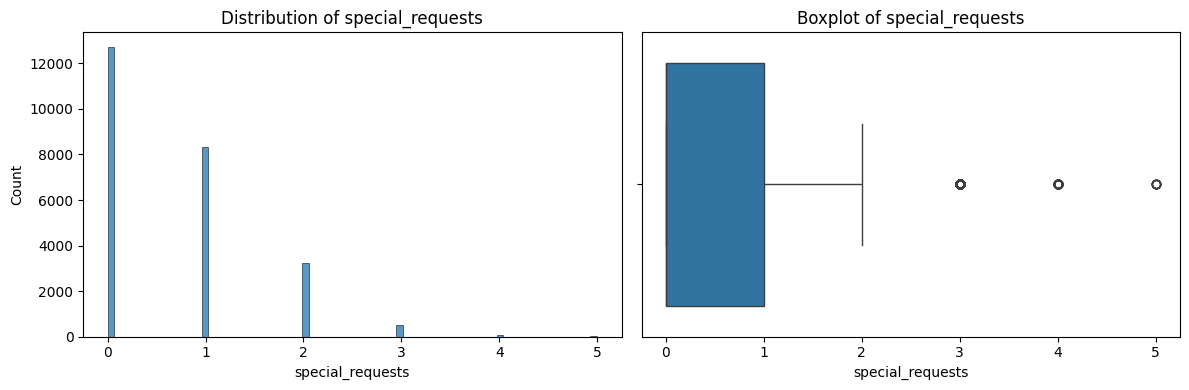

In [16]:
# Write your code here

plot_numeric(numerical_cols)

Sebagian besar atribut numerik memiliki distribusi yang tidak simetris (*skewed*), dengan mayoritas observasi terkonsentrasi pada nilai relatif kecil dan sebagian kecil observasi memiliki nilai yang lebih tinggi.

- `num_adults` didominasi oleh pemesanan dengan 2 orang dewasa. Nilai 1, 3, dan 4 relatif lebih jarang ditemukan.
- `num_children` hampir seluruhnya bernilai 0. Namun, terdapat sebagian kecil observasi dengan jumlah anak yang lebih tinggi dibandingkan mayoritas data.
- `weekend_nights` dan `weekday_nights` umumnya menunjukkan durasi menginap yang relatif pendek. Meskipun demikian, terdapat sebagian kecil pemesanan dengan durasi menginap jauh lebih panjang.
- `days_before_arrival` memiliki distribusi yang sangat miring ke kanan. Sebagian besar pemesanan dilakukan relatif dekat dengan tanggal kedatangan, sementara sebagian lainnya dilakukan jauh lebih awal.
- `prior_cancellations` dan `prior_completed_bookings` sangat didominasi oleh nilai 0. Sebagian kecil observasi memiliki jumlah riwayat pembatalan maupun pemesanan yang jauh lebih tinggi.
- `nightly_rate_idr` terkonsentrasi pada rentang tarif tertentu, tetapi memiliki ekor distribusi ke arah nilai yang lebih tinggi. Selain itu, terdapat lonjakan observasi pada nilai 0 yang merepresentasikan *complimentary stay*.
- `special_requests` umumnya memiliki nilai 0–2, sedangkan jumlah permintaan khusus yang lebih tinggi relatif jarang ditemukan.

Berdasarkan boxplot, beberapa atribut menunjukkan titik observasi di luar *whisker* yang mengindikasikan *potential outliers*. Namun, nilai ekstrem pada atribut seperti durasi menginap, waktu pemesanan sebelum kedatangan, maupun jumlah riwayat pemesanan dapat mencerminkan variasi alami karakteristik pelanggan. Oleh karena itu, penanganan outlier perlu mempertimbangkan karakteristik dan distribusi masing-masing atribut.

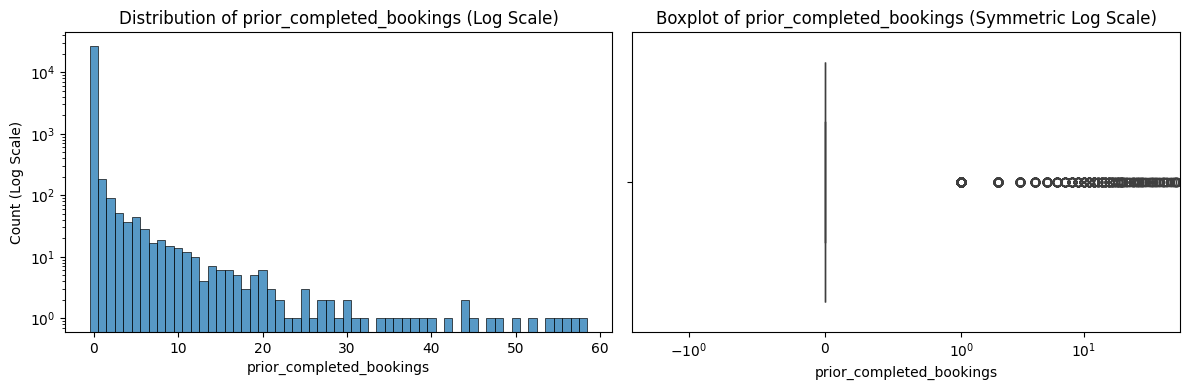

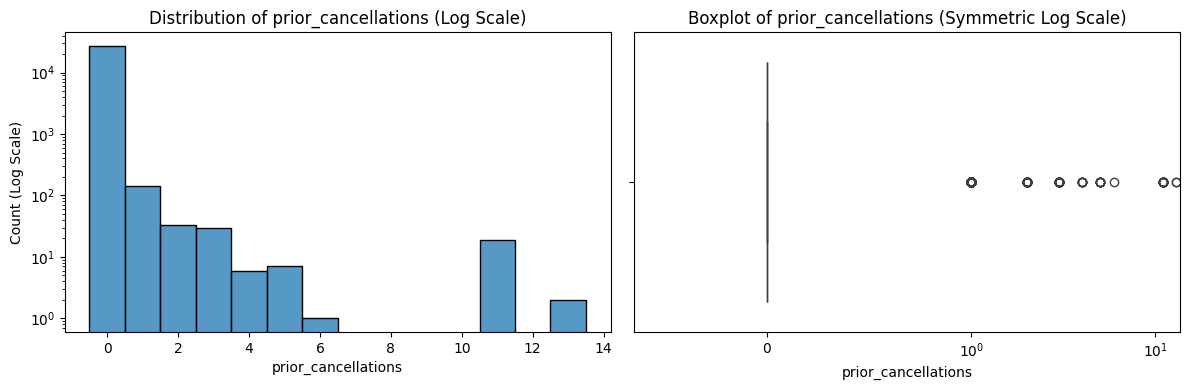

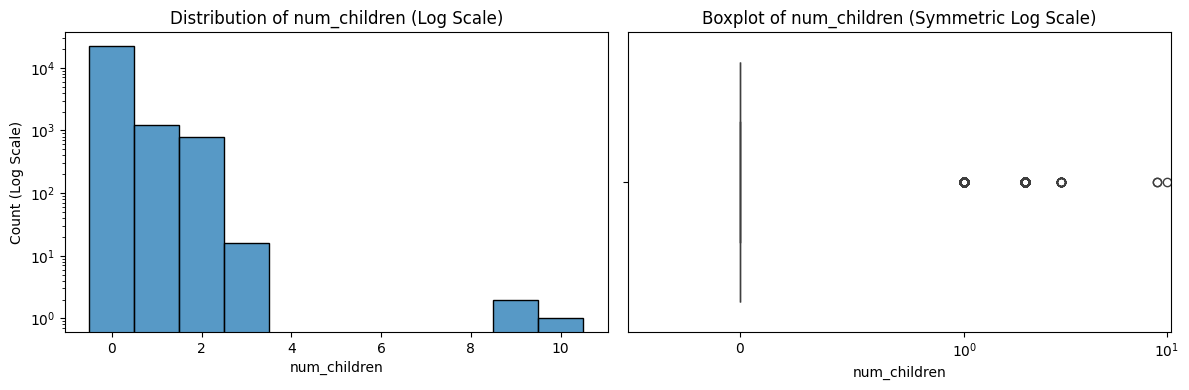

In [17]:

# Variabel count yang memiliki distribusi sangat skewed
skewed_count_cols = [
    'prior_completed_bookings',
    'prior_cancellations',
    'num_children'
]

plot_numeric(skewed_count_cols, log_columns=skewed_count_cols)

Ketiga atribut di atas hampir seluruhnya bernilai 0. Skala log memperlihatkan ekor yang sangat tipis ke nilai yang jauh di atas mayoritas data. Atribut ini sangat skewed sehingga perlu diperhatikan saat scaling dan penanganan outlier.

**Atribut kategorikal**

In [18]:
display(train_df[categorical_cols].describe().T)

,count,unique,top,freq
meal_package,25613,4,Breakfast,19654
room_category,26371,7,Type B,20447
booking_channel,27373,5,Online Travel Agent,17511


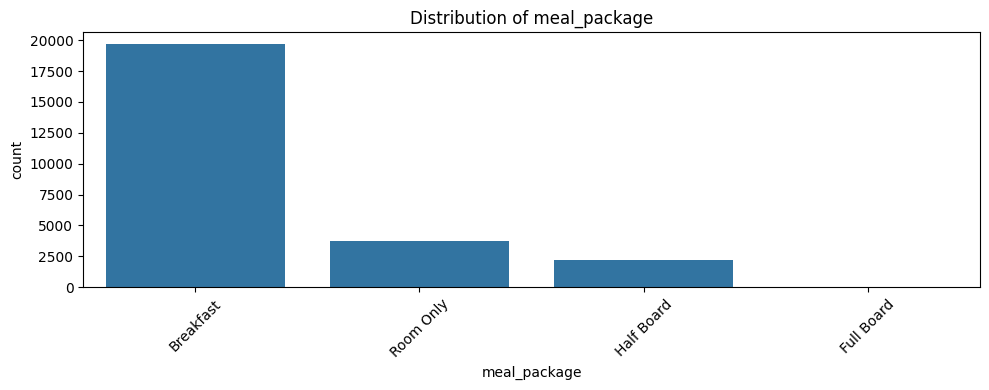

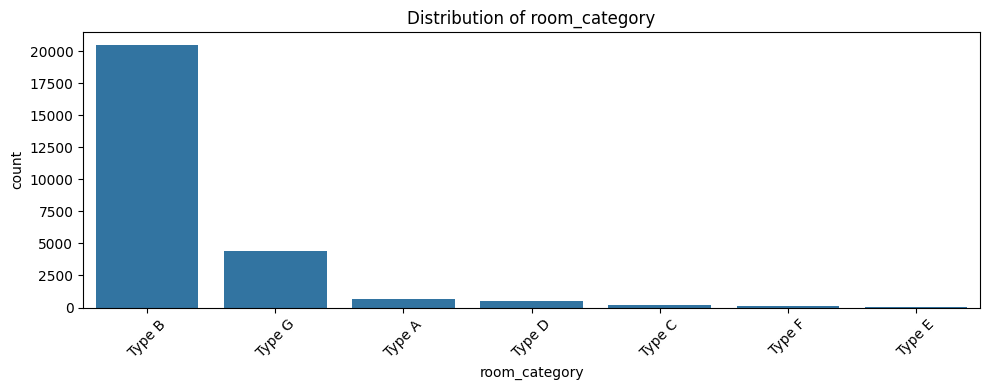

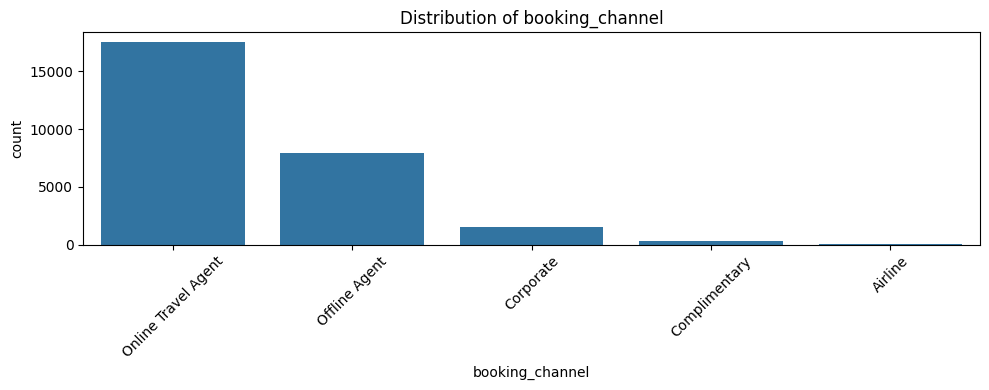

In [19]:
plot_count(categorical_cols)

`meal_package` didominasi Breakfast, sedangkan Full Board hampir tidak muncul. `room_category` didominasi Type B, diikuti Type G, dan tipe lainnya jarang. `booking_channel` didominasi Online Travel Agent, lalu Offline Agent, sedangkan Corporate, Complimentary, dan Airline sedikit. Kategori yang sangat jarang berpotensi menyulitkan encoding dan estimasi model.

**Atribut Binary**

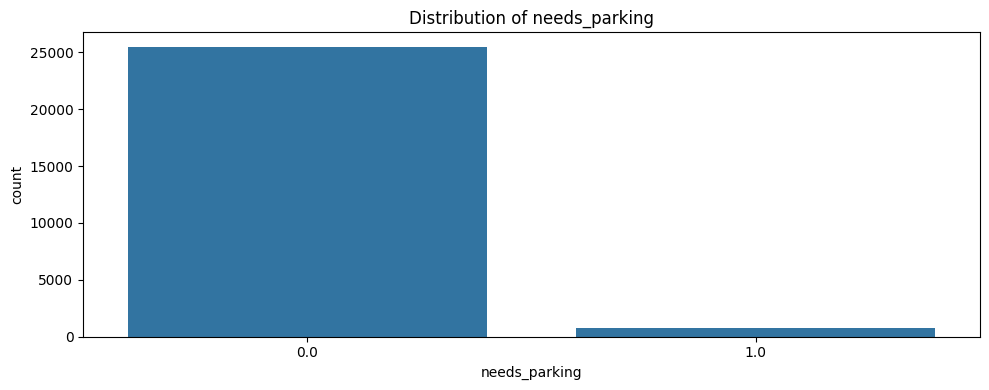

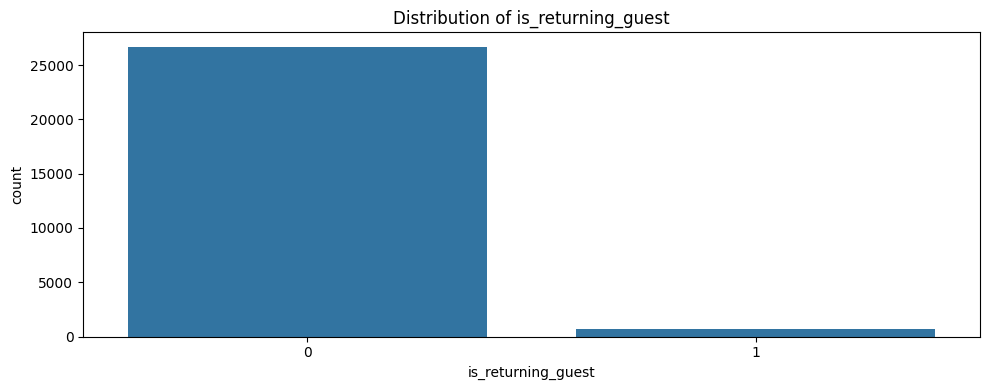

In [20]:
plot_count(binary_cols, rotate=0)

`needs_parking` dan `is_returning_guest` sangat tidak seimbang: hampir semua booking bernilai 0 (tidak butuh parkir dan bukan tamu berulang).

**Atribut Temporal**

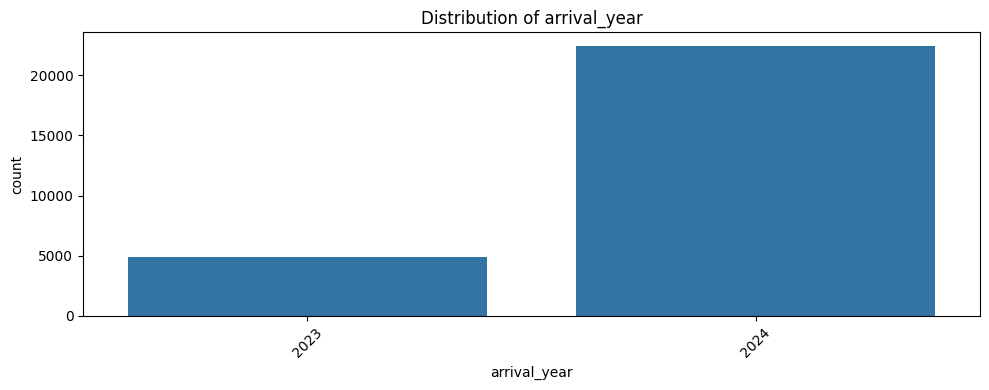

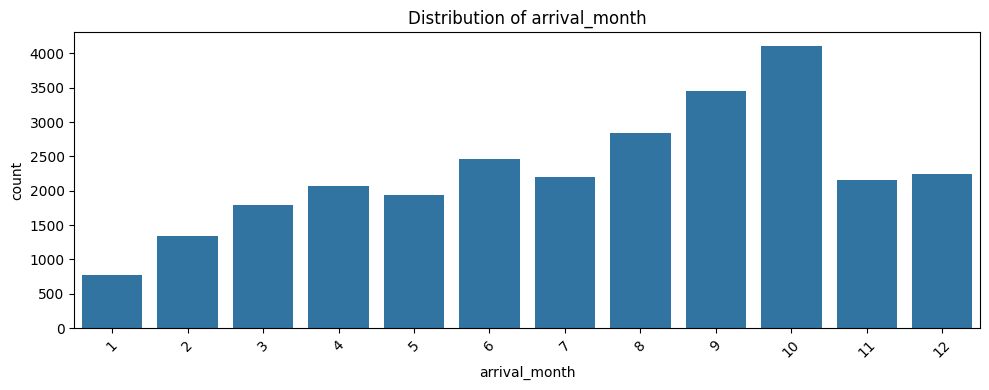

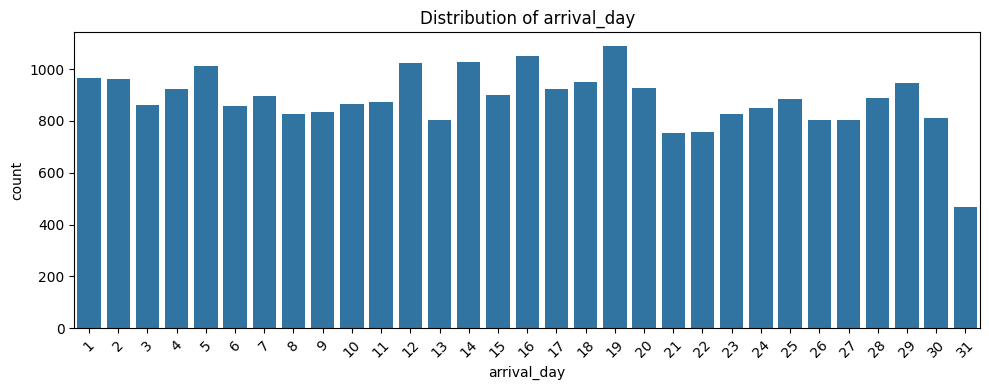

In [21]:
plot_count(temporal_cols, order='value')

Data jauh lebih banyak di 2024 dibanding 2023. Jumlah booking per bulan cenderung naik dari awal tahun sampai puncak di Oktober, lalu turun sedikit. Pola bulanan ini mungkin terpengaruh distribusi tahun yang tidak merata. `arrival_day` relatif merata, dan tanggal 31 paling sedikit karena tidak semua bulan memiliki tanggal 31.

**Atribut Target**

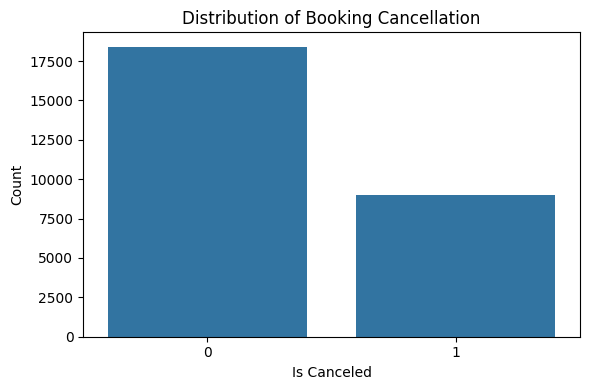

is_canceled
0    67.234136
1    32.765864
Name: proportion, dtype: float64

In [22]:
plot_target()

Target cukup tidak seimbang, yaitu 67,2% tidak dibatalkan dan 32,8% dibatalkan. Imbalance: akan digunakan stratified split dan F1-score untuk menilai performance model.

**Analisis hubungan antarfitur**

Korelasi antaratribut numerik dianalisis menggunakan correlation heatmap

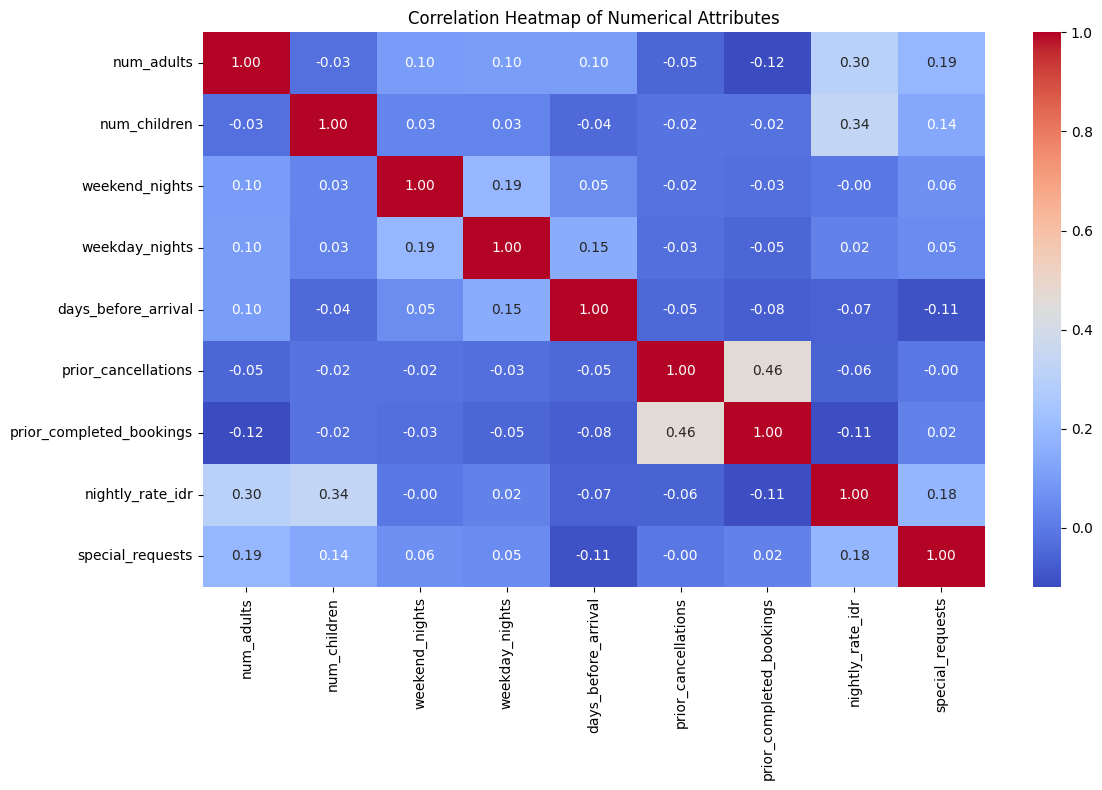

In [23]:
plot_correlation(numerical_cols)

Korelasi antaratribut numerik umumnya lemah. Yang paling menonjol adalah `prior_cancellations` dengan `prior_completed_bookings` (0,46), serta `nightly_rate_idr` dengan `num_children` (0,34) dan `num_adults` (0,30), yang wajar karena tarif naik seiring jumlah tamu. Tidak ada pasangan dengan korelasi sangat tinggi, jadi multikolinearitas bukan masalah besar.

Distribusi kombinasi antaratribut kategorikal dianalisis menggunakan crosstab heatmap

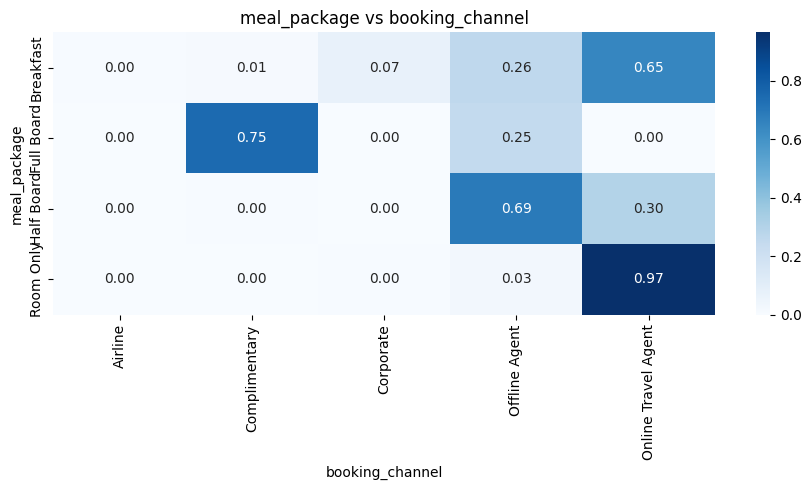

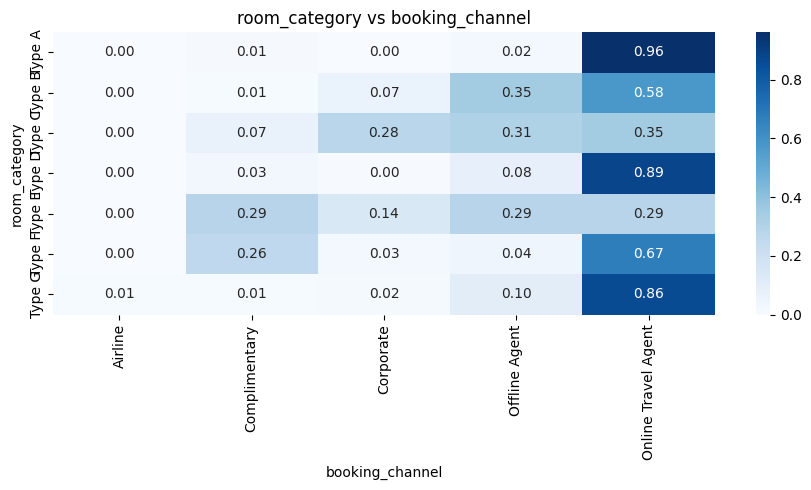

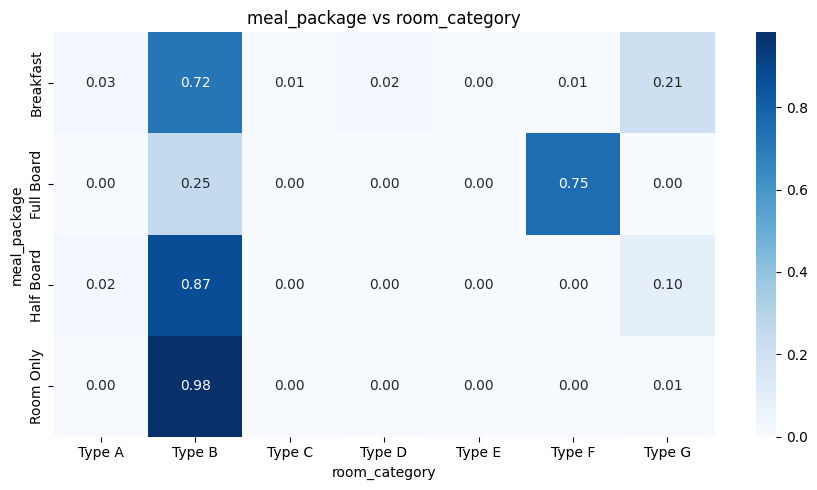

In [24]:
categorical_pairs = [
    ("meal_package", "booking_channel"),
    ("room_category", "booking_channel"),
    ("meal_package", "room_category")
]

plot_crosstab(categorical_pairs)

Antaratribut kategorikal terdapat keterkaitan yang kuat. Room Only 97% dipesan lewat Online Travel Agent dan 98% berada di Type B. Full Board 75% berasal dari Complimentary dan 75% berada di Type F. Half Board 69% berasal dari Offline Agent. Artinya sebagian informasi antarkategori saling tumpang tindih.

Distribusi atribut numerik berdasarkan kategori dianalisis menggunakan boxplot

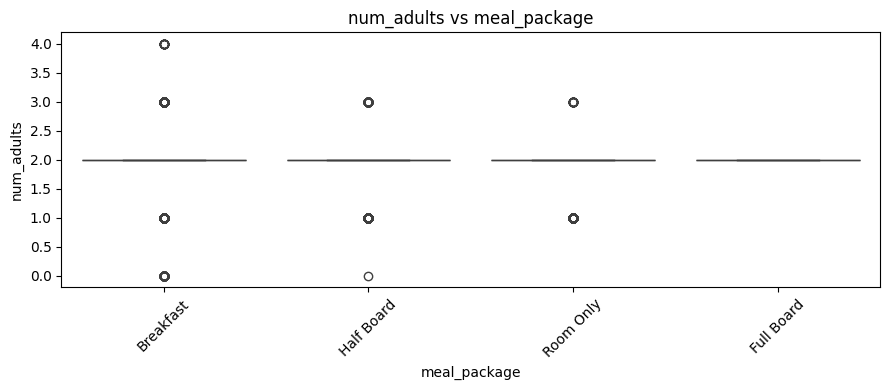

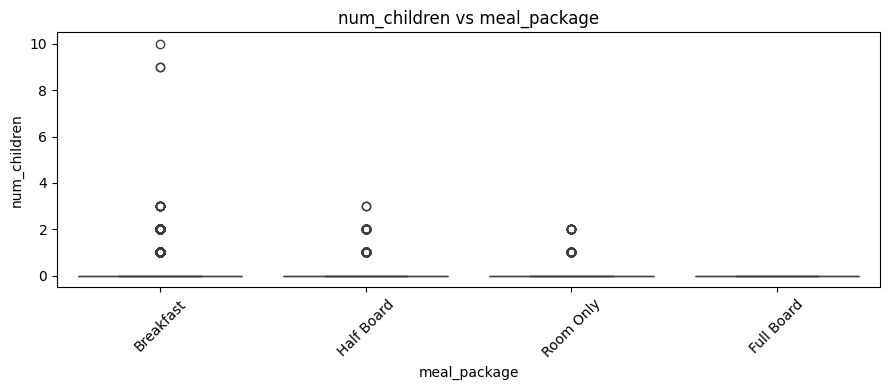

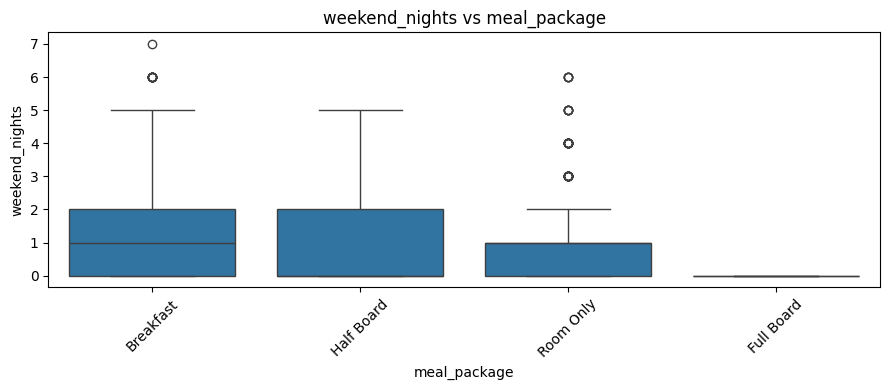

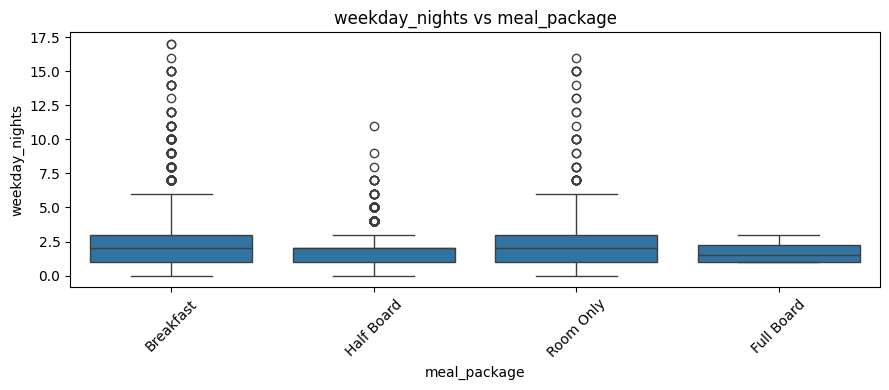

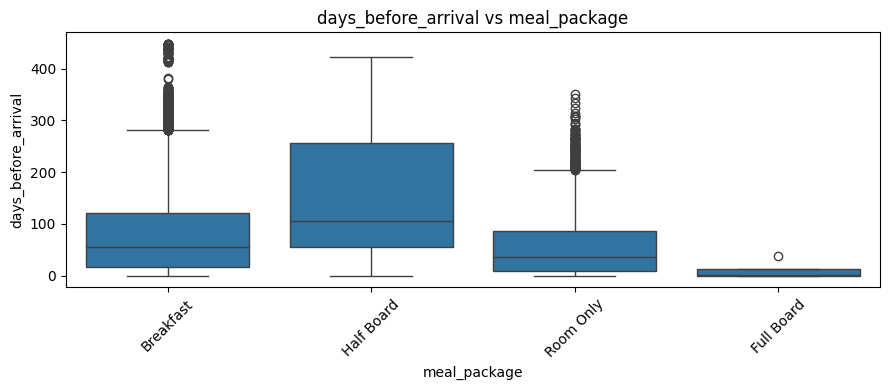

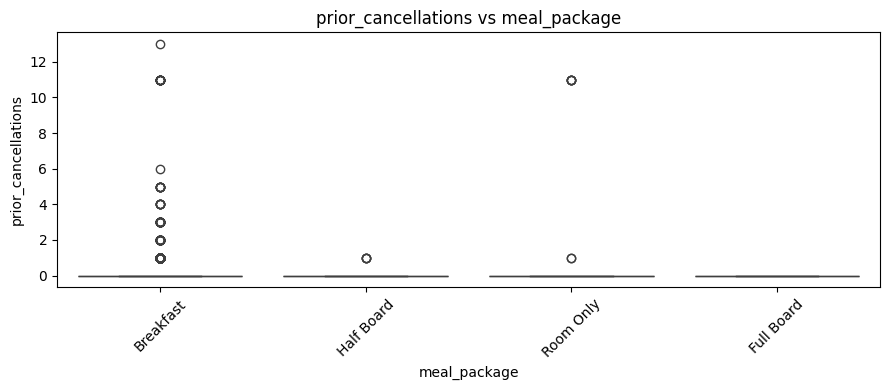

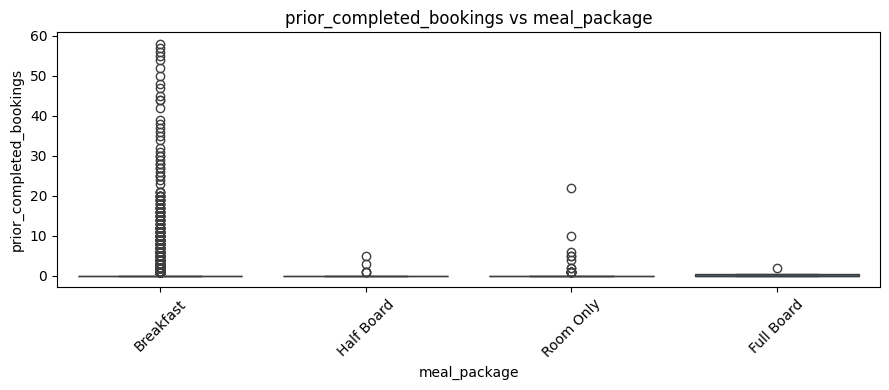

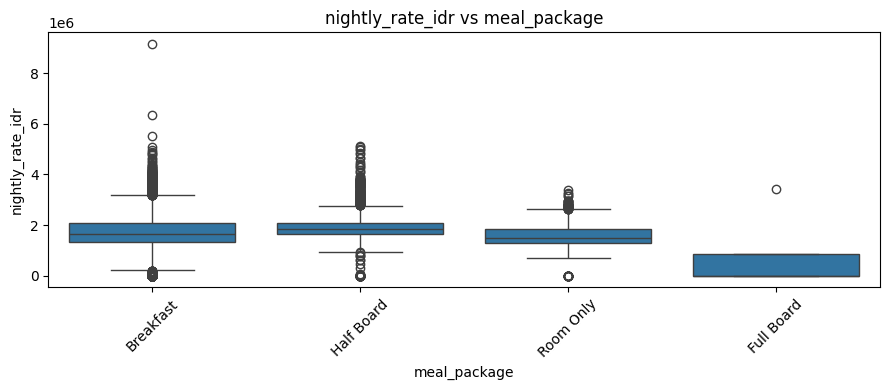

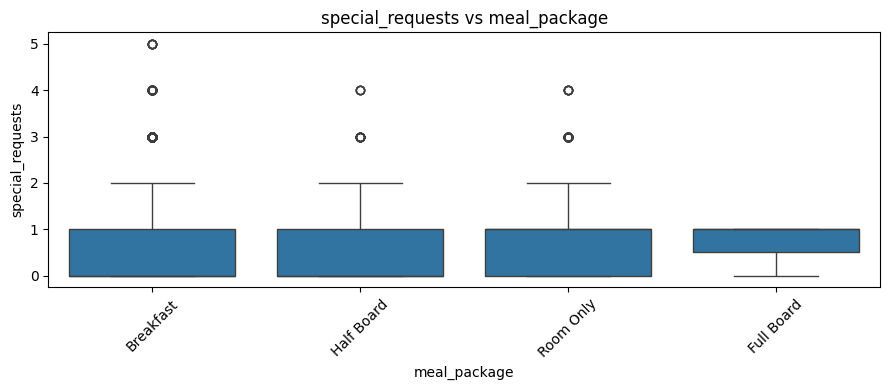

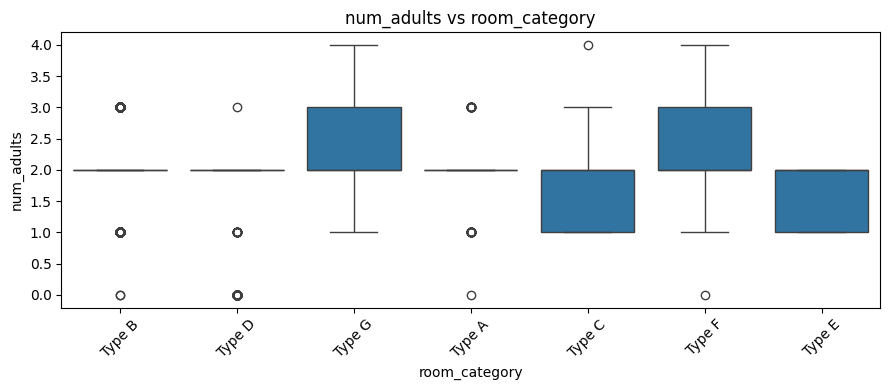

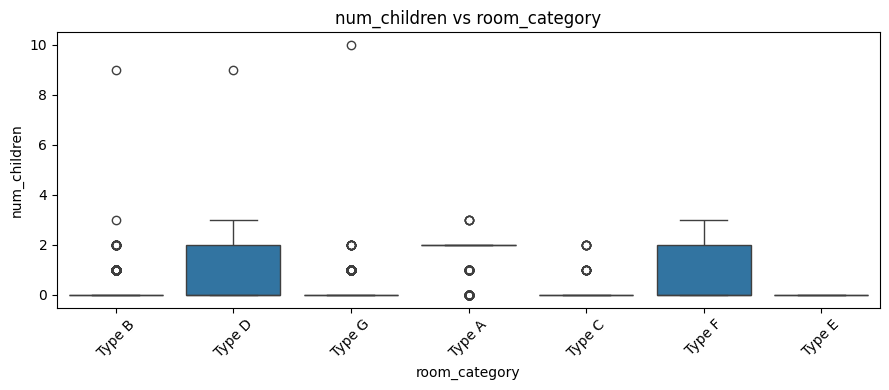

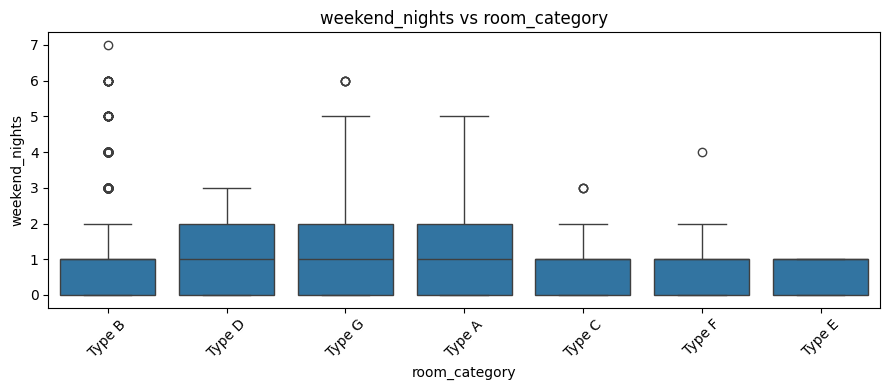

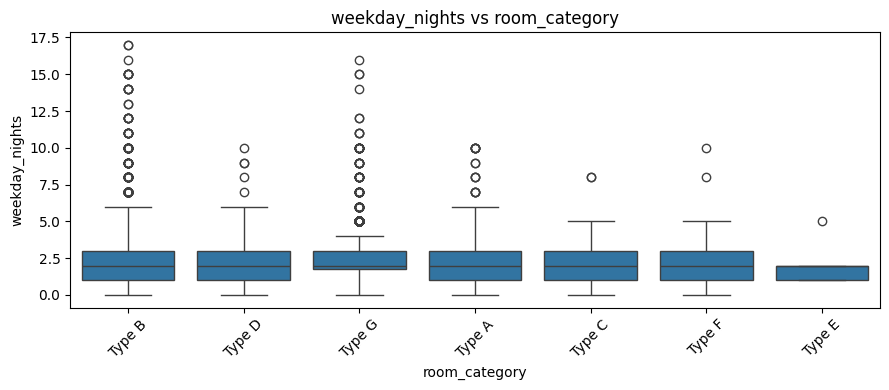

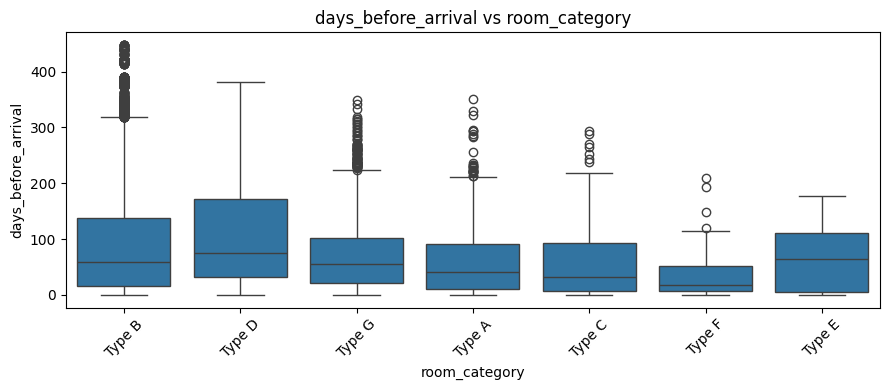

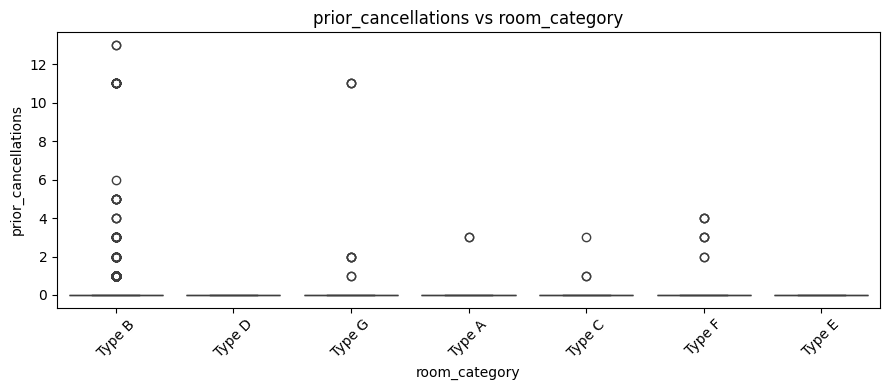

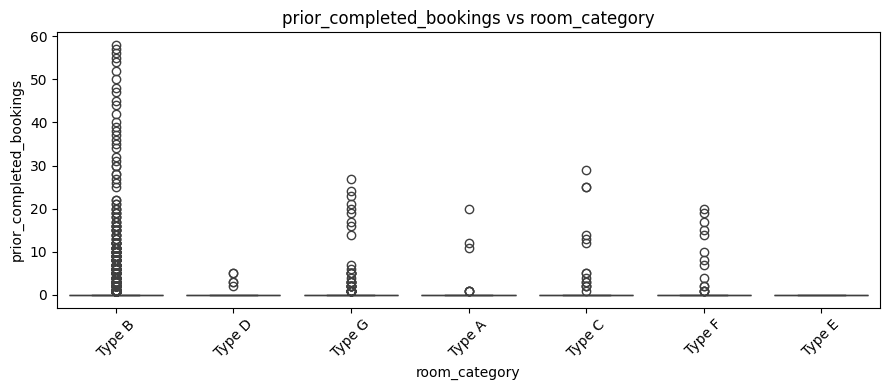

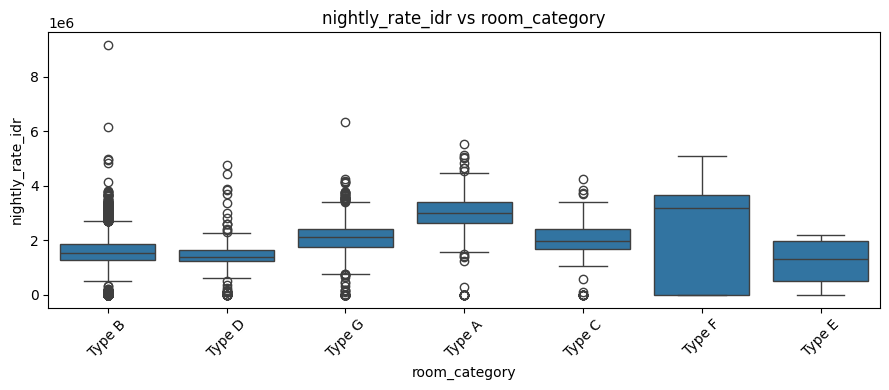

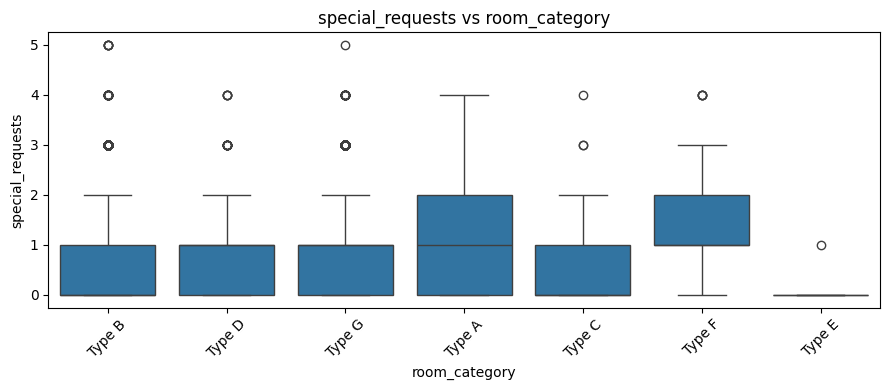

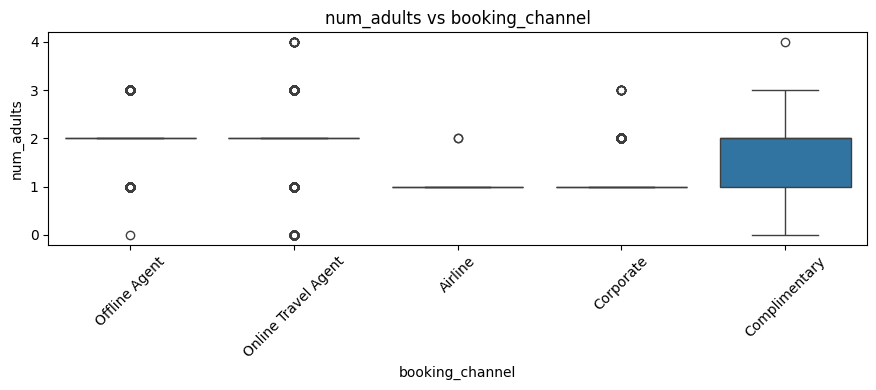

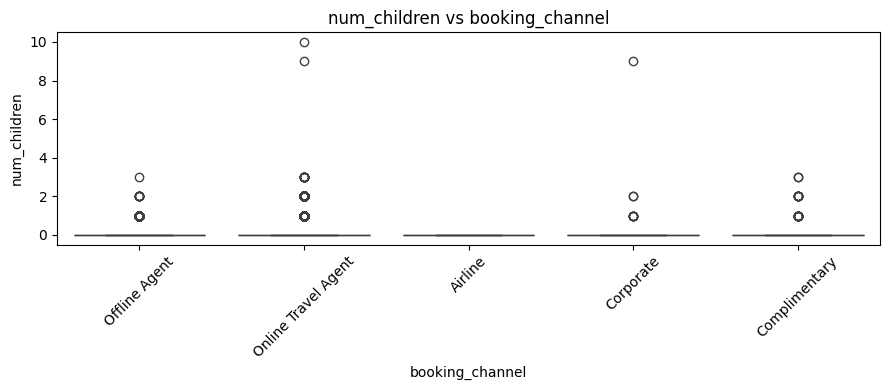

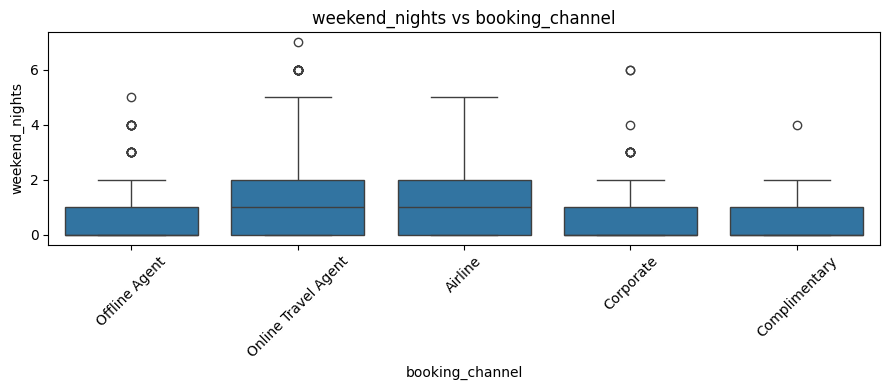

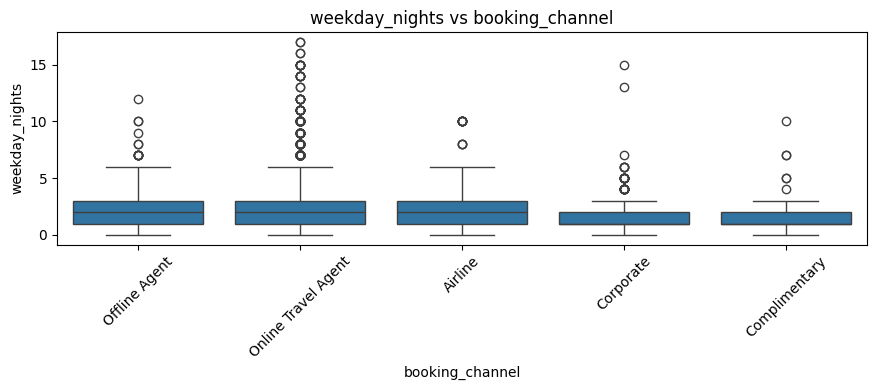

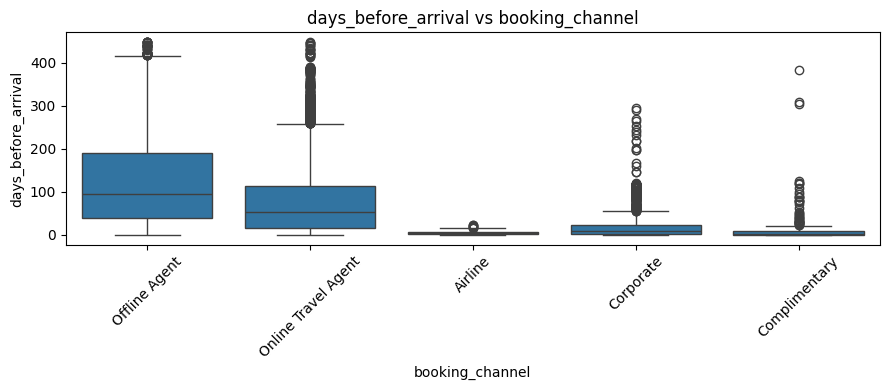

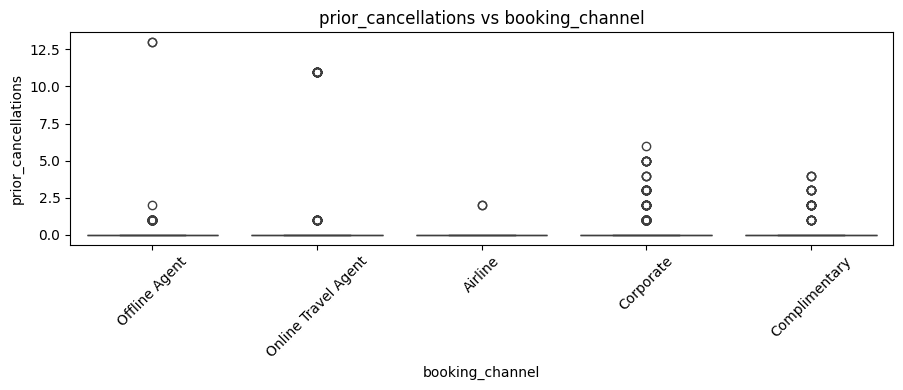

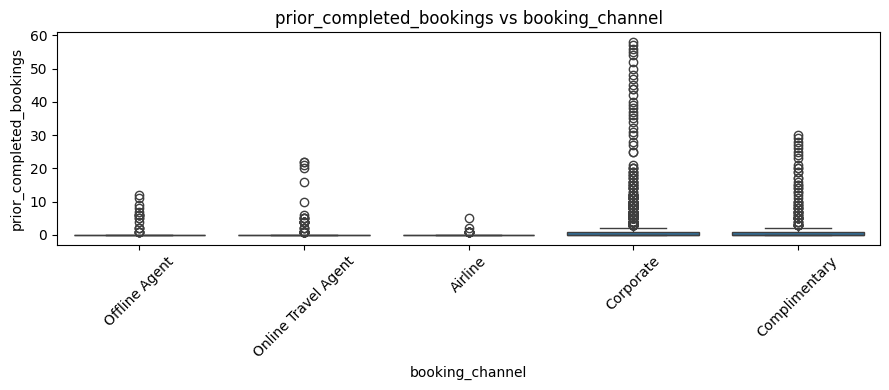

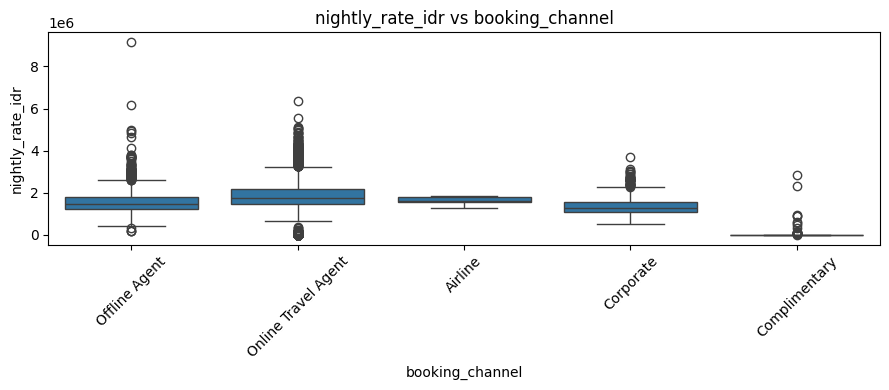

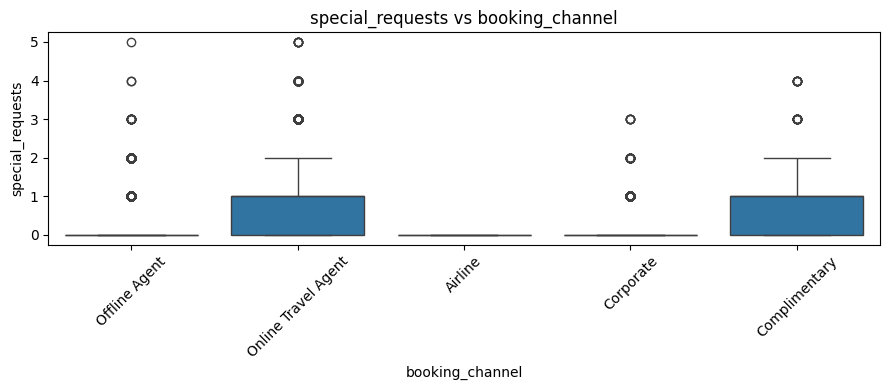

In [25]:
plot_box(categorical_cols, numerical_cols)

`nightly_rate_idr`: Type A paling mahal, Type B dan D paling murah. `days_before_arrival` paling panjang pada Offline Agent dan Half Board, dan sangat pendek pada Airline, Corporate, Complimentary, dan Full Board. `prior_completed_bookings` yang tinggi terutama muncul pada Corporate dan Complimentary (tamu berulang). Type G dan F cenderung dipesan lebih banyak dewasa, dan Type A, D, dan F lebih sering terdapat anak.

**Analisis hubungan setiap fitur dengan target**

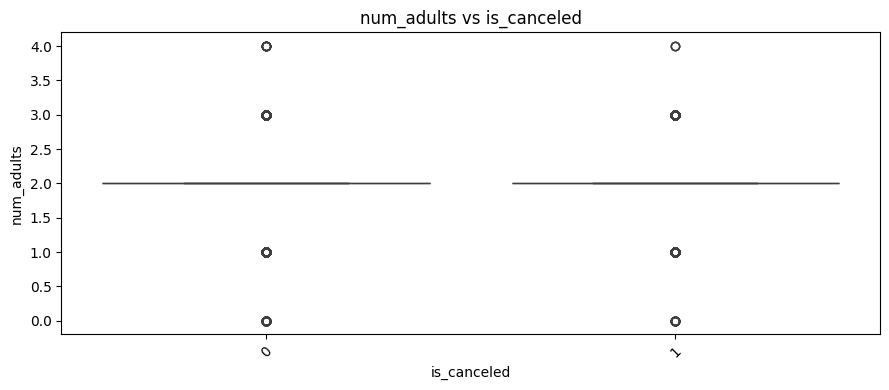

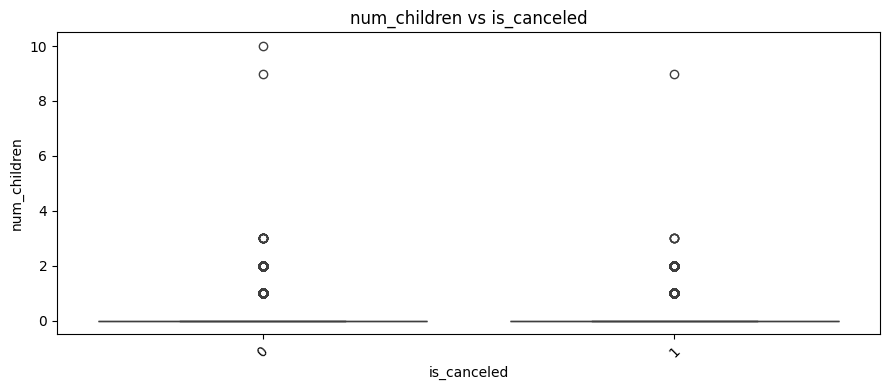

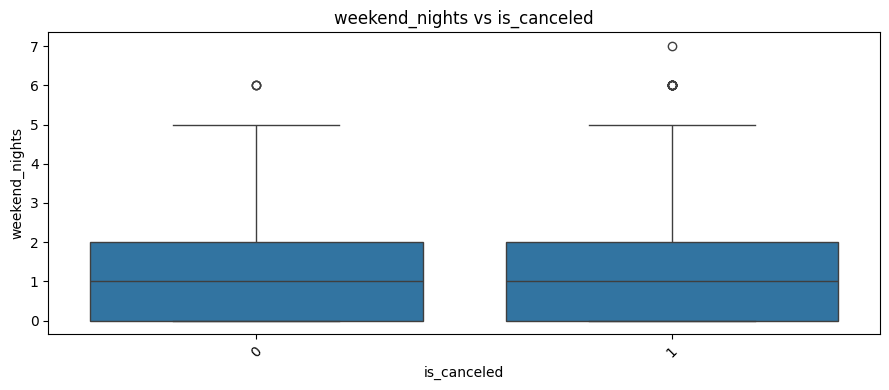

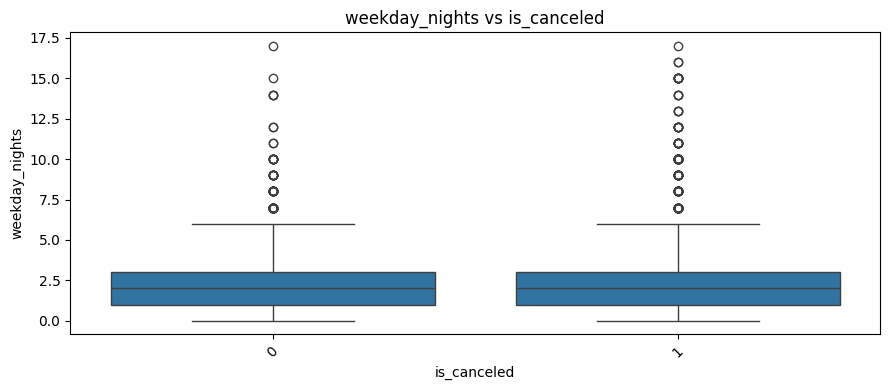

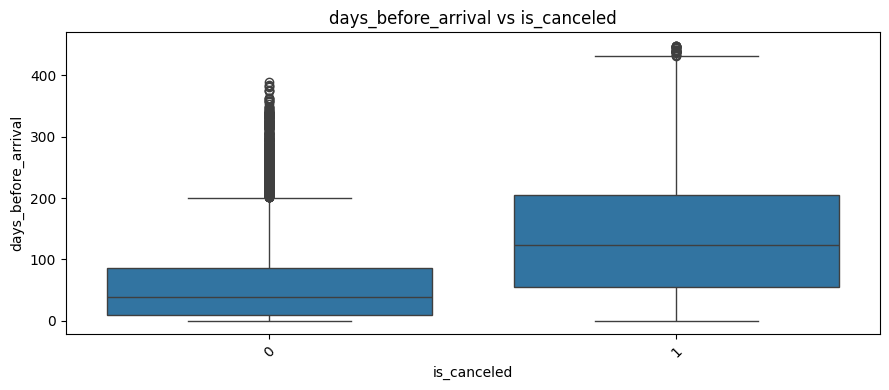

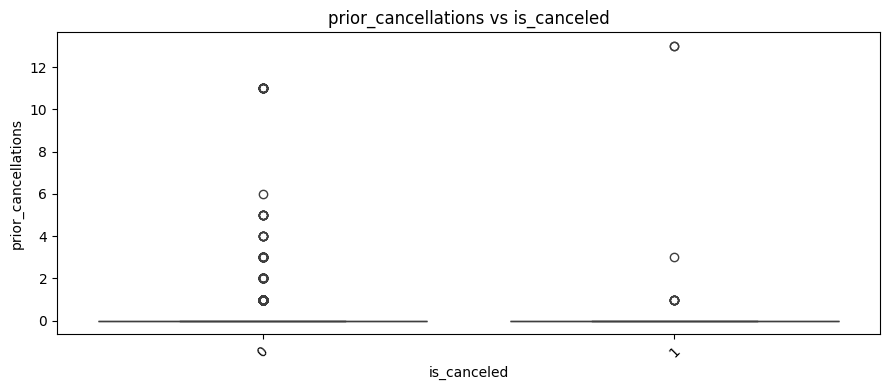

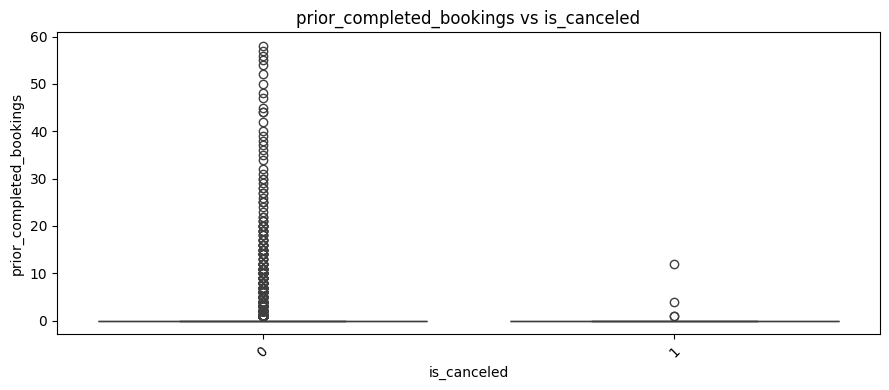

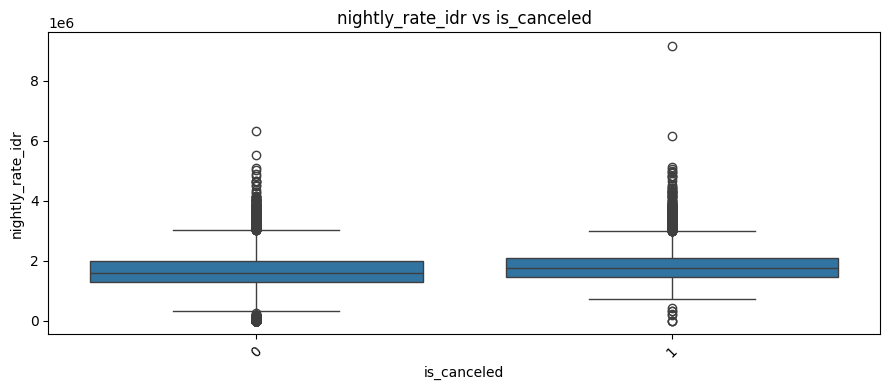

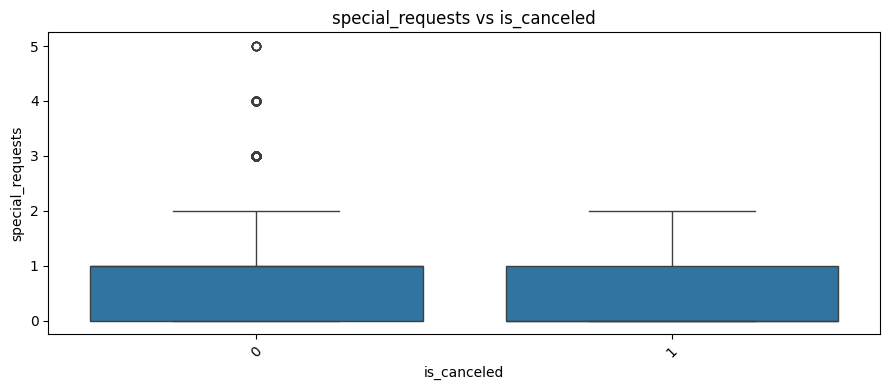

In [26]:
plot_box(CFG.TARGET, numerical_cols)

days_before_arrival adalah pembeda paling jelas: median booking yang dibatalkan jauh lebih tinggi daripada yang tidak dibatalkan. Hampir semua booking yang dibatalkan punya prior_completed_bookings = 0, dan special_requests yang tinggi (3 ke atas) hanya muncul pada kelas tidak dibatalkan. nightly_rate_idr pada kelas dibatalkan sedikit lebih tinggi. Atribut lain (num_adults, num_children, weekend_nights, weekday_nights, prior_cancellations) distribusinya mirip antarkelas sehingga pembeda individualnya lemah.

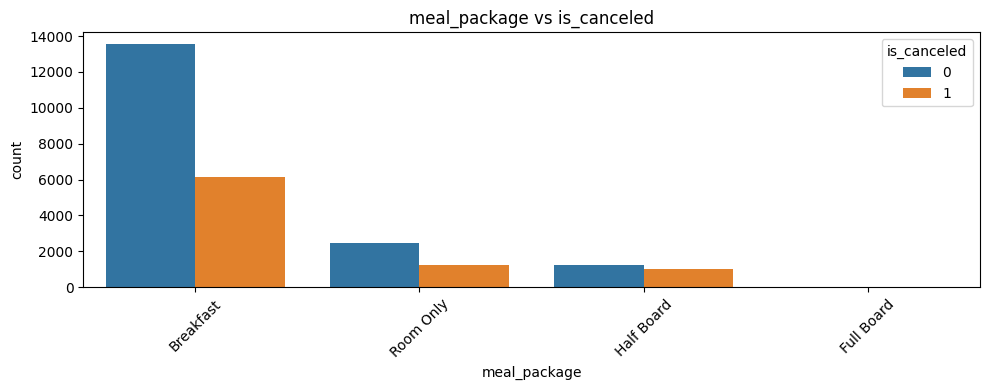

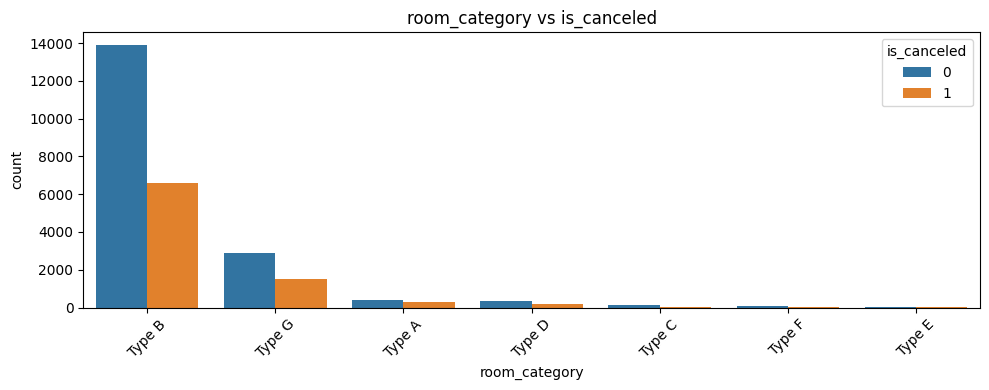

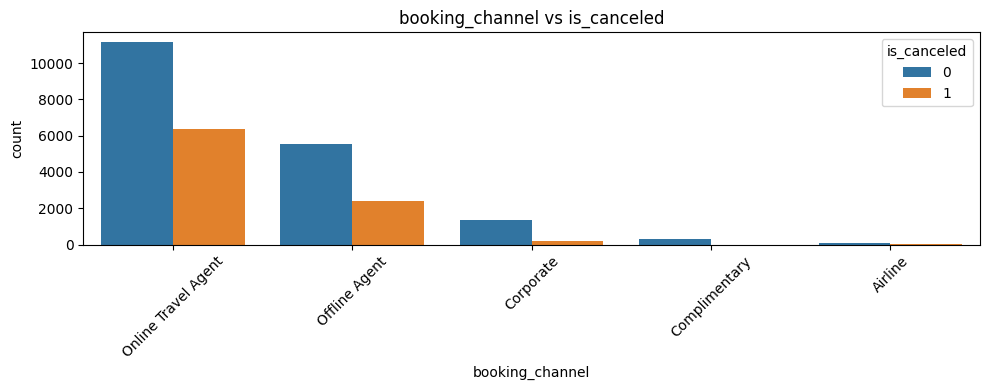

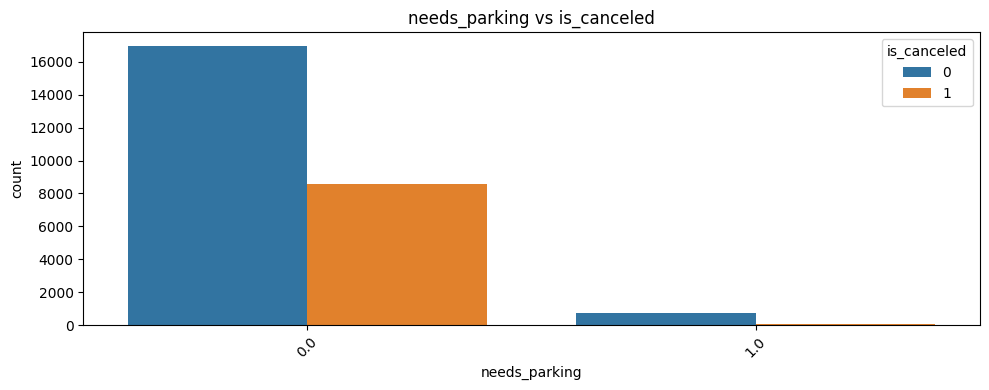

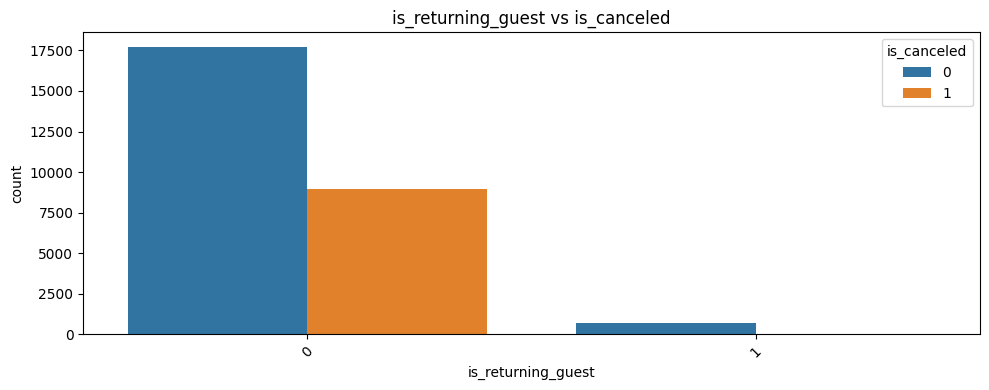

In [27]:
plot_count(categorical_cols + binary_cols, hue=CFG.TARGET)

Tamu yang butuh parkir (needs_parking = 1) dan tamu berulang (is_returning_guest = 1) hampir tidak pernah membatalkan. Pembatalan paling rendah pada Corporate dan Complimentary. Half Board punya proporsi batal paling tinggi dibanding Breakfast dan Room Only. Online Travel Agent sedikit lebih tinggi proporsi batalnya dibanding Offline Agent. Proporsi batal antar room_category relatif mirip.

## Verify Data Quality

This part covers completeness, consistency, and the validity of values.

Fungsi pemeriksaan kualitas data.

- `missing_report` menampilkan jumlah dan persentase missing value pada satu DataFrame
- `check_duplicates` menghitung baris duplikat pada `train_df`, dengan `feature_cols` sebagai daftar fitur
- `check_structure` membandingkan kolom dan ID antara `train_df` dan `test_df`
- `check_validity` memeriksa nilai binary, negatif, non-integer, tanggal kedatangan, dan kategori yang diizinkan

In [28]:
def missing_report(data):
    report = pd.DataFrame({
        "Missing Count": data.isnull().sum(),
        "Missing Percentage (%)": data.isnull().mean() * 100
    })
    report = report[report["Missing Count"] > 0].sort_values(by="Missing Percentage (%)", ascending=False)

    display(report)
    rows = data.isnull().any(axis=1).sum()
    print("Rows with missing values:", rows)
    print("Row missing percentage:", rows / len(data) * 100)

def check_duplicates(data, feature_cols):
    print("Duplicate rows:", data.duplicated().sum())
    print("Duplicate rows tanpa id:", data.drop(columns=[CFG.ID_COLUMN]).duplicated().sum())
    print("Duplicate rows tanpa id dan label:", data[feature_cols].duplicated().sum())
    print("Duplicate booking IDs:", data[CFG.ID_COLUMN].duplicated().sum())

def check_structure(train, test):
    print("Same features:", set(train.columns) - {CFG.TARGET} == set(test.columns))
    print("\nTrain columns:", train.columns.tolist())
    print("\nTest columns:", test.columns.tolist())
    print("Overlapping IDs:", len(set(train[CFG.ID_COLUMN]) & set(test[CFG.ID_COLUMN])))

def check_validity(data, binary, numeric, integer, valid_categories):
    for col in binary:
        invalid = data[~data[col].isin([0, 1]) & data[col].notna()]
        print(f"{col}: {len(invalid)} invalid values")

    for col in numeric:
        print(f"{col}: {len(data[data[col] < 0])} negative values")

    for col in integer:
        invalid = data[data[col].notna() & (data[col] % 1 != 0)]
        print(f"{col}: {len(invalid)} non-integer values")

    dates = pd.to_datetime(
        data[["arrival_year", "arrival_month", "arrival_day"]]
        .rename(columns={"arrival_year": "year", "arrival_month": "month", "arrival_day": "day"}),
        errors="coerce"
    )
    print("Invalid arrival months:", len(data[~data["arrival_month"].between(1, 12)]))
    print("Invalid arrival days:", len(data[~data["arrival_day"].between(1, 31)]))
    print("Invalid arrival dates:", dates.isna().sum())

    for col, valid_values in valid_categories.items():
        invalid = data[~data[col].isin(valid_values) & data[col].notna()]
        print(f"{col}: {len(invalid)} invalid values")
        if len(invalid) > 0:
            display(invalid[col].value_counts())

**Missing value**

Pemeriksaan missing values dilakukan untuk mengidentifikasi atribut yang memiliki data kosong serta jumlah dan persentasenya.

In [29]:
# Write your code here

missing_report(train_df)

,Missing Count,Missing Percentage (%)
num_children,3035,11.087568
special_requests,2500,9.133087
nightly_rate_idr,2038,7.445293
meal_package,1760,6.429693
days_before_arrival,1123,4.102583
needs_parking,1082,3.952800
room_category,1002,3.660541
num_adults,809,2.955467


Rows with missing values: 10737
Row missing percentage: 39.22478354582984


In [30]:
missing_report(test_df)

,Missing Count,Missing Percentage (%)
num_children,747,10.914670
special_requests,593,8.664524
nightly_rate_idr,540,7.890123
meal_package,442,6.458212
days_before_arrival,290,4.237288
needs_parking,247,3.609001
room_category,242,3.535944
num_adults,180,2.630041


Rows with missing values: 2669
Row missing percentage: 38.99766218585622


**Pada data train:**

8 dari 17 fitur punya nilai missing, mulai dari 2,96% (`num_adults`) sampai 11,09% (`num_children`).

Total baris yang memiliki setidaknya satu missing value berjumlah berjumlah 10.737 baris (sekitar 39% dari data train).

**Pada data test:**

8 dari 17 fitur juga memiliki missing values, dengan persentase berkisar antara 2,63% (`num_adults`) hingga 10,91% (`num_children`).

Total baris yang memiliki setidaknya satu missing value berjumlah 2.669 baris (sekitar 39% dari data test).

**Dengan demikian, missing values ditemukan pada data train maupun test dengan proporsi baris yang terdampak relatif serupa.**


**Konsistensi**

Pemeriksaan dilakukan terhadap duplicate records, keunikan booking identifier, konsistensi nilai kategorikal, serta kesesuaian struktur antara training dan testing dataset.

In [31]:
# Cek baris duplikat
check_duplicates(train_df, feature_cols)

Duplicate rows: 0
Duplicate rows tanpa id: 64
Duplicate rows tanpa id dan label: 66
Duplicate booking IDs: 0


In [32]:
# Cek nilai kategorikal
for col in categorical_cols:
    print(f"\n{col}:")
    print(sorted(train_df[col].dropna().unique()))


meal_package:
['Breakfast', 'Full Board', 'Half Board', 'Room Only']

room_category:
['Type A', 'Type B', 'Type C', 'Type D', 'Type E', 'Type F', 'Type G']

booking_channel:
['Airline', 'Complimentary', 'Corporate', 'Offline Agent', 'Online Travel Agent']


In [33]:
# Cek struktur atribut train_df dan test_df
check_structure(train_df, test_df)

Same features: True

Train columns: ['id', 'num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'meal_package', 'needs_parking', 'room_category', 'days_before_arrival', 'arrival_year', 'arrival_month', 'arrival_day', 'booking_channel', 'is_returning_guest', 'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr', 'special_requests', 'is_canceled']

Test columns: ['id', 'num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'meal_package', 'needs_parking', 'room_category', 'days_before_arrival', 'arrival_year', 'arrival_month', 'arrival_day', 'booking_channel', 'is_returning_guest', 'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr', 'special_requests']
Overlapping IDs: 0


Hasil pemeriksaan menunjukkan terdapat 66 baris  dengan nilai seluruh fitur yang identik, meskipun memiliki ID berbeda. Dari jumlah tersebut, 64 baris memiliki nilai target yang sama, sedangkan 2 baris lainnya memiliki nilai target yang berbeda. Hal ini menunjukkan adanya potensi duplikasi observasi serta inkonsistensi label pada 2 observasi.

Selain itu, tidak ditemukan booking ID duplikat dan tidak terlihat inkonsistensi pada nilai kategorikal (tidak ada perbedaan lower/upper case, format penamaan, dll). Struktur atribut antara data train tanpa kolom target dan data test juga identik.

**Validitas**

Pemeriksaan validitas dilakukan dengan membandingkan nilai aktual dalam dataset dengan karakteristik dan batasan atribut. Pemeriksaan mencakup nilai binary, rentang nilai numerik, representasi bilangan bulat, validitas tanggal kedatangan, dan kategori yang diperbolehkan pada laman kaggle.

In [34]:
# Atribut yang seharusnya bilangan bulat (berdasarkan laman kaggle) perlu diperiksa apakah terdapat nilai desimal
integer_cols = [
    "num_adults",
    "num_children",
    "days_before_arrival",
    "special_requests"
]

# Atribut kategorikal harus memiliki nilai yang diperbolehkan menurut deskripsi pada laman kaggle
valid_categories = {
    "room_category": [
        "Type A", "Type B", "Type C", "Type D",
        "Type E", "Type F", "Type G"
    ],

    "booking_channel": [
        "Online Travel Agent",
        "Offline Agent",
        "Corporate",
        "Airline",
        "Complimentary"
    ]
}

# Periksa atribut binary, numerik, integer, tanggal, dan kategorikal
check_validity(train_df, binary_cols, numerical_cols, integer_cols, valid_categories)

needs_parking: 0 invalid values
is_returning_guest: 0 invalid values
num_adults: 0 negative values
num_children: 0 negative values
weekend_nights: 0 negative values
weekday_nights: 0 negative values
days_before_arrival: 0 negative values
prior_cancellations: 0 negative values
prior_completed_bookings: 0 negative values
nightly_rate_idr: 0 negative values
special_requests: 0 negative values
num_adults: 0 non-integer values
num_children: 0 non-integer values
days_before_arrival: 0 non-integer values
special_requests: 0 non-integer values
Invalid arrival months: 0
Invalid arrival days: 0
Invalid arrival dates: 0
room_category: 0 invalid values
booking_channel: 0 invalid values


Hasil pemeriksaan menunjukkan seluruh atribut memiliki nilai yang valid sebagaimana yang diharapkan menurut deskripsi data di laman kaggle.

---

# Training and Validation Split <a name="4"></a>

---

The split comes before data preparation so that validation data stays unseen. Only `train.csv` is split, and `test.csv` serves the Kaggle submission alone.

### Duplicates

This part covers repeated records. Dilakukan sebelum splitting data untuk menghindari observasi duplikat tersebar pada kedua subset.

Dari EDA diketahui terdapat 64 (0,23%) baris ganda (seluruh atribut kecuali id identik).

**Penanganan:**

Untuk 64 baris yang memiliki seluruh nilai atribut sama kecuali `id` (potensi duplikasi observasi) akan ditangani dengan menghapus salah satu baris karena jumlahnya cukup sedikit.





In [35]:
n_before = len(train_df)
train_df = train_df.drop_duplicates(subset=list(feature_cols) + [CFG.TARGET], keep="first").copy()

print(f"Baris sebelum: {n_before} | sesudah: {len(train_df)} | dihapus: {n_before - len(train_df)}")

Baris sebelum: 27373 | sesudah: 27309 | dihapus: 64


In [36]:
# Stratified split pada kolom target agar proporsi kelas target terjaga
train_set, val_set = train_test_split(
    train_df,
    test_size=CFG.TEST_SIZE,
    random_state=CFG.SEED,
    stratify=train_df[CFG.TARGET] #agar membagi data berdasarkan rasio nilai di kolom target_col
)

print("Training set:", train_set.shape)
print("Validation set:", val_set.shape)

Training set: (21847, 19)
Validation set: (5462, 19)


---

# Data Preparation <a name="5"></a>

---

Each process below applies where the data calls for it, and the Insights block under it records the reason for the decision.

Preparation steps may use `sklearn`. Every statistic comes from the training split only, then transforms the other sets.

## Select Data

Selection decides which records and attributes stay in the analysis.

Atribut yang dikeluarkan adalah atribut ID karena hanya berfungsi sebagai identifier dan atribut `is_cancelled` karena berupa atribut target yang akan diprediksi.

Baris duplikat sejumlah 64 baris pada data train telah dibuang pada duplicate handling sebelum train-test split.

In [37]:
# Write your code here
feature_cols = train_df.drop(columns=[CFG.ID_COLUMN, CFG.TARGET]).columns

X_train = train_set[feature_cols].copy()
X_validation = val_set[feature_cols].copy()
X_test = test_df[feature_cols].copy()

y_train = train_set[CFG.TARGET].astype(int).to_numpy()
y_validation = val_set[CFG.TARGET].astype(int).to_numpy()

# ID disimpan terpisah untuk Error Analysis dan file submission Kaggle
id_train = train_set[CFG.ID_COLUMN].to_numpy()
id_validation = val_set[CFG.ID_COLUMN].to_numpy()
id_test = test_df[CFG.ID_COLUMN].to_numpy()

print("Jumlah fitur:", len(feature_cols))
print("Train:", X_train.shape)
print("Validation:", X_validation.shape)
print("Test:", X_test.shape)

Jumlah fitur: 17
Train: (21847, 17)
Validation: (5462, 17)
Test: (6844, 17)


## Clean Data

Cleaning raises data quality to the level the chosen models need.

### Missing Values

This part covers missing values, if any.

Dari EDA diketahui bahwa Missing value ada pada 8 dari 17 fitur dan memengaruhi sekitar 39% baris, baik di train maupun test. Karena jumlahnya yang cukup besar, missing value akan ditangani dengan cara imputasi.

**Aturan yang digunakan untuk imputasi:**
1. Atribut numerik (`num_adults`, `num_children`, `special_requests`, `days_before_arrival`) diimputasi dengan median karena distribusinya miring dan median tahan terhadap outlier.
2. Atribut kategorikal/biner (`meal_package`, `room_category`, `needs_parking`) memakai modus.
3. `nightly_rate_idr` diimputasi dengan median per `booking_channel` karena tarif sangat bergantung pada channel.
4. Kolom yang missing tetap diberi indikator `<kolom>_missing` agar informasi "nilai hilang" tetap tersedia bagi model.

Untuk menghindari leakage, semua nilai pengganti dihitung dari data train, lalu dipakai juga untuk validation dan test.

In [38]:
def apply_all(func, *args, **kwargs):
    return tuple(func(frame, *args, **kwargs) for frame in (X_train, X_validation, X_test))

def add_missing_indicators(columns):
    columns = as_list(columns)
    for frame in (X_train, X_validation, X_test):
        for col in columns:
            frame[f'{col}_missing'] = frame[col].isnull().astype(int)

def impute(columns, strategy='median', by=None):
    for col in as_list(columns):
        overall = X_train[col].median() if strategy == 'median' else X_train[col].mode()[0]
        group_fill = X_train.groupby(by)[col].median() if by else None

        for frame in (X_train, X_validation, X_test):
            values = frame[col].fillna(frame[by].map(group_fill)) if by else frame[col]
            frame[col] = values.fillna(overall)

In [39]:
# Write your code here

numerical_impute_cols = [
    'num_adults',
    'num_children',
    'special_requests',
    'days_before_arrival'
]

categorical_impute_cols = [
    'meal_package',
    'room_category',
    'needs_parking'
]

group_impute_col = 'nightly_rate_idr'
group_col = 'booking_channel'

missing_indicator_cols = (
    numerical_impute_cols
    + categorical_impute_cols
    + [group_impute_col]
)

# Hitung dari X_train, diterapkan ke X_train, X_validation, dan X_test
add_missing_indicators(missing_indicator_cols)

impute(numerical_impute_cols, 'median')
impute(categorical_impute_cols, 'most_frequent')
impute(group_impute_col, 'median', by=group_col)

In [40]:
def check_missing(indicator_cols):
    print("=== Missing Values setelah imputasi ===")

    for name, df in [("Train", X_train), ("Validation", X_validation), ("Test", X_test)]:
        print(f"\n{name}")
        print("Remaining missing values:", df.isnull().sum().sum())

        print("\nMissing Indicators:")
        for col in indicator_cols:
            indicator = f"{col}_missing"
            print(f"{indicator}: {df[indicator].sum()} rows")

check_missing(missing_indicator_cols)

=== Missing Values setelah imputasi ===

Train
Remaining missing values: 0

Missing Indicators:
num_adults_missing: 648 rows
num_children_missing: 2457 rows
special_requests_missing: 2004 rows
days_before_arrival_missing: 887 rows
meal_package_missing: 1416 rows
room_category_missing: 811 rows
needs_parking_missing: 882 rows
nightly_rate_idr_missing: 1596 rows

Validation
Remaining missing values: 0

Missing Indicators:
num_adults_missing: 161 rows
num_children_missing: 578 rows
special_requests_missing: 495 rows
days_before_arrival_missing: 233 rows
meal_package_missing: 344 rows
room_category_missing: 191 rows
needs_parking_missing: 200 rows
nightly_rate_idr_missing: 396 rows

Test
Remaining missing values: 0

Missing Indicators:
num_adults_missing: 180 rows
num_children_missing: 747 rows
special_requests_missing: 593 rows
days_before_arrival_missing: 290 rows
meal_package_missing: 442 rows
room_category_missing: 242 rows
needs_parking_missing: 247 rows
nightly_rate_idr_missing: 540 

Missing value sudah ditangani dengan informasi missing tetap dipertahankan melalui missing indicator.

### Duplicates

This part covers repeated records.

Penanganan baris duplikat sudah dilakukan sebelum splitting data (lihat bagian *Training and Validation Split*), agar observasi duplikat tidak tersebar pada training dan validation set.

Pada bagian ini dilakukan pemeriksaan ulang bahwa tidak ada baris dengan fitur dan label yang sama pada training dan validation set.

In [41]:
# Pemeriksaan ulang setelah splitting
def check_split_duplicates(train_part, val_part, columns):
    n_duplicates = pd.concat([train_part, val_part]).duplicated(subset=columns).sum()
    print("Duplicate rows (fitur dan label sama) pada training + validation set:", n_duplicates)
    assert n_duplicates == 0

check_split_duplicates(train_set, val_set, list(feature_cols) + [CFG.TARGET])

Duplicate rows (fitur dan label sama) pada training + validation set: 0


### Outliers

This part covers values far from the rest of the data.

Dari EDA pada identifikasi outlier dan karakteristik distribusi masing-masing atribut, diketahui bahwa terdapat outlier pada `weekend_nights`, `weekday_nights`, `days_before_arrival`, `nightly_rate_idr`, `num_children`.

**Penanganan:**

Penerapan Winsorizing pada `weekend_nights`, `weekday_nights`, `days_before_arrival`, `nightly_rate_idr`, dan `num_children`. Nilai yang melebihi persentil ke-99,5 pada data training dipotong hingga mencapai batas tersebut untuk membatasi pengaruh nilai ekstrem tanpa menghapus observasi dari dataset. Khusus `nightly_rate_idr`, hanya batas atas yang diterapkan karena nilai 0 tetap dipertahankan sebagai nilai yang bermakna, yaitu *complimentary stay*.

Untuk mencegah *data leakage*, batas winsorizing dihitung hanya berdasarkan data training, kemudian diterapkan secara konsisten pada data validation dan test.

In [42]:
def cap_outliers(columns, quantile=0.995):
    columns = as_list(columns)
    upper = X_train[columns].quantile(quantile).apply(np.floor).astype('int64')

    report = pd.DataFrame({
        "batas_atas": upper,
        "max_train": X_train[columns].max(),
        "n_dipotong_train": (X_train[columns] > upper).sum(),
        "n_dipotong_val": (X_validation[columns] > upper).sum(),
        "n_dipotong_test": (X_test[columns] > upper).sum()
    })

    for frame in (X_train, X_validation, X_test):
        frame[columns] = frame[columns].clip(upper=upper, axis=1)

    return report

In [43]:
# Write your code here
clip_cols = [
    "weekend_nights",
    "weekday_nights",
    "days_before_arrival",
    "nightly_rate_idr",
    "num_children"
]

# Hitung dari X_train, diterapkan ke X_train, X_validation, dan X_test
display(cap_outliers(clip_cols, CFG.UPPER_Q))


,batas_atas,max_train,n_dipotong_train,n_dipotong_val,n_dipotong_test
weekend_nights,4,6.0,33,9,10
weekday_nights,8,16.0,100,19,23
days_before_arrival,381,448.0,105,27,26
nightly_rate_idr,3678770,9165000.0,110,41,30
num_children,2,10.0,13,6,3


 Batas atas yang diperoleh adalah 4 (`weekend_nights`), 8 (`weekday_nights`), 381 (`days_before_arrival`), 3.678.770 (`nightly_rate_idr`), dan 2 (`num_children`), yang memotong 0,06%–0,50% observasi training per atribut.

### Data Errors

This part covers wrong types, inconsistent labels, and impossible values.

Dari EDA diketahui tidak terdapat impossible values. Namun terjadi inkonsistensi label dan wrong types.

**Inkonsistensi label**

Hasil pemeriksaan menunjukkan terdapat 2 baris  dengan nilai seluruh fitur yang identik, namun memiliki nilai target yang berbeda. Hal ini menunjukkan adanya inkonsistensi label pada 2 observasi yang sama. Baris tersebut tetap dipertahankan karena tidak dapat dipastikan label mana yang salah, dan perbedaan label dapat mencerminkan ketidakpastian yang memang ada pada data.

**Wrong types**

Bila mengacu pada deskripsi data di laman kaggle, diperlukan penyesuaian tipe data `num_adults`, `num_children`, `nightly_rate_idr`, dan `special_request` bertipe integer, dan `needs_parking` juga menjadi integer karena berupa nilai biner. Lalu, `meal_package`, `room_category`, dan `booking_channel` adalah tipe category.


In [44]:
def adjust_types(df, integer_cols, binary_cols, category_cols):
    df = df.copy()
    df[integer_cols] = df[integer_cols].astype('int64')
    df[binary_cols] = df[binary_cols].astype('int8')
    df[category_cols] = df[category_cols].astype('category')
    return df

X_train, X_validation, X_test = apply_all(
    adjust_types,
    numerical_cols + temporal_cols,
    binary_cols,
    categorical_cols
)

In [45]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21847 entries, 12716 to 3185
Data columns (total 25 columns):
 #   Column                       Non-Null Count  Dtype   
---  ------                       --------------  -----   
 0   num_adults                   21847 non-null  int64   
 1   num_children                 21847 non-null  int64   
 2   weekend_nights               21847 non-null  int64   
 3   weekday_nights               21847 non-null  int64   
 4   meal_package                 21847 non-null  category
 5   needs_parking                21847 non-null  int8    
 6   room_category                21847 non-null  category
 7   days_before_arrival          21847 non-null  int64   
 8   arrival_year                 21847 non-null  int64   
 9   arrival_month                21847 non-null  int64   
 10  arrival_day                  21847 non-null  int64   
 11  booking_channel              21847 non-null  category
 12  is_returning_guest           21847 non-null  int8    
 13  pri

Seluruh atribut sudah memiliki tipe yang sesuai dengan deskripsi data di laman kaggle

## Construct Data

Construction derives attributes and transforms values for modeling.

### Attribute Construction

<!-- rubric v3: derived columns, rate_per_guest_night -->

This part covers new attributes derived from existing ones.

**Atribut baru**

Berdasarkan hasil EDA, dilakukan pembentukan atribut baru (*feature engineering*) dengan mempertimbangkan distribusi dan korelasi antaratribut.

| Atribut Baru | Pembentukan | Tujuan dan alasan |
|---|---|---|
| `total_nights` | `weekend_nights + weekday_nights` | Merepresentasikan total durasi menginap dalam satu reservasi. Kedua atribut penyusun memiliki distribusi yang terkonsentrasi pada durasi pendek. |
| `total_guests` | `num_adults + num_children` | Merepresentasikan total jumlah tamu dalam satu reservasi. Dipertimbangkan karena `nightly_rate_idr` memiliki korelasi positif dengan `num_adults` (0,30) dan `num_children` (0,34). |
| `is_complimentary_stay` | `nightly_rate_idr == 0` | Mengidentifikasi reservasi dengan tarif menginap gratis (*complimentary stay*). EDA menunjukkan lonjakan observasi pada nilai 0 yang merupakan kondisi valid. |
| `has_completed_booking_history` | `prior_completed_bookings > 0` | Mengidentifikasi pelanggan yang memiliki riwayat pemesanan selesai. Hampir seluruh observasi booking yang dibatalkan memiliki `prior_completed_bookings = 0`. |
| `total_prior_bookings` | `prior_completed_bookings + prior_cancellations` | Merepresentasikan total riwayat pemesanan pelanggan. Kedua atribut memiliki korelasi positif sebesar 0,46. |
| `prior_cancellation_rate` | `prior_cancellations / total_prior_bookings` | Mengukur proporsi pembatalan dari seluruh riwayat pemesanan pelanggan, sehingga dapat membedakan pelanggan berdasarkan kecenderungan pembatalan sebelumnya. |
| `has_many_special_requests` | `special_requests >= 3` | Mengidentifikasi reservasi dengan jumlah permintaan khusus yang relatif tinggi. EDA menunjukkan bahwa observasi dengan `special_requests` sebanyak 3 atau lebih hanya ditemukan pada kelas booking yang tidak dibatalkan. |
| `arrival_day_of_week` | Ekstraksi hari dalam minggu dari `arrival_year`, `arrival_month`, dan `arrival_day` | Merepresentasikan hari kedatangan untuk mengeksplorasi kemungkinan pola pembatalan berdasarkan hari. |

**Catatan redundansi:** `total_nights`, `total_guests`, dan `total_prior_bookings` merupakan penjumlahan dari atribut penyusunnya sehingga secara linear redundan dengan atribut tersebut. Redundansi ini akan ditangani oleh regularisasi pada Logistic Regression (L1/L2/Elastic Net) dan oleh PCA pada varian reduksi dimensi.

In [46]:
def engineer(df):
    df = df.copy()

    df["total_nights"] = df["weekend_nights"] + df["weekday_nights"]
    df["total_guests"] = df["num_adults"] + df["num_children"]
    df["is_complimentary_stay"] = (df["nightly_rate_idr"] == 0).astype("int8")
    df["has_completed_booking_history"] = (df["prior_completed_bookings"] > 0).astype("int8")
    df["total_prior_bookings"] = df["prior_completed_bookings"] + df["prior_cancellations"]

    # Pelanggan tanpa riwayat pemesanan sebelumnya diberi nilai kosong (`NaN`) karena proporsi pembatalan tidak dapat dihitung.
    df["prior_cancellation_rate"] = df["prior_cancellations"] / df["total_prior_bookings"].replace(0, np.nan)
    df["has_many_special_requests"] = (df["special_requests"] >= 3).astype("int8")

    arrival_date = pd.to_datetime(
        df[["arrival_year", "arrival_month", "arrival_day"]]
        .astype("float64")
        .rename(columns={"arrival_year": "year", "arrival_month": "month", "arrival_day": "day"}),
        errors="coerce"
    )
    df["arrival_day_of_week"] = arrival_date.dt.dayofweek

    return df

X_train, X_validation, X_test = apply_all(engineer)

In [47]:
new_features = [
    "total_nights",
    "total_guests",
    "is_complimentary_stay",
    "has_completed_booking_history",
    "total_prior_bookings",
    "prior_cancellation_rate",
    "has_many_special_requests",
    "arrival_day_of_week"
]

display(X_train[new_features].head())

,total_nights,total_guests,is_complimentary_stay,has_completed_booking_history,total_prior_bookings,prior_cancellation_rate,has_many_special_requests,arrival_day_of_week
12716,7,2,0,0,0,NaN,0,5
958,3,2,0,0,0,NaN,0,5
7218,3,2,0,0,0,NaN,0,4
26365,2,1,0,0,0,NaN,0,0
27344,4,3,0,0,0,NaN,0,5


**Transformasi**

Dari EDA, diketahui bahwa terdapat atribut yang sangat skew, yaitu `prior_cancellations` dan `prior_completed_bookings`

**Penanganan:**

Dilakukan transformasi logaritmik pada `prior_cancellations` dan `prior_completed_bookings` menggunakan fungsi `log1p` untuk mengurangi kemencengan distribusi tanpa menghilangkan informasi mengenai jumlah riwayat pemesanan maupun pembatalan.

In [48]:
def log_transform(df, columns):
    df = df.copy()
    df[columns] = np.log1p(df[columns].astype("float64"))
    return df

log_cols = [
    "prior_cancellations",
    "prior_completed_bookings"
]

X_train, X_validation, X_test = apply_all(log_transform, log_cols)

In [49]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21847 entries, 12716 to 3185
Data columns (total 33 columns):
 #   Column                         Non-Null Count  Dtype   
---  ------                         --------------  -----   
 0   num_adults                     21847 non-null  int64   
 1   num_children                   21847 non-null  int64   
 2   weekend_nights                 21847 non-null  int64   
 3   weekday_nights                 21847 non-null  int64   
 4   meal_package                   21847 non-null  category
 5   needs_parking                  21847 non-null  int8    
 6   room_category                  21847 non-null  category
 7   days_before_arrival            21847 non-null  int64   
 8   arrival_year                   21847 non-null  int64   
 9   arrival_month                  21847 non-null  int64   
 10  arrival_day                    21847 non-null  int64   
 11  booking_channel                21847 non-null  category
 12  is_returning_guest             218

### Feature Scaling

This part covers normalization to the range 0 to 1 and standardization.

Dari EDA diketahui atribut numerik memiliki skala yang sangat berbeda (mis. `nightly_rate_idr` dalam jutaan rupiah, `num_adults` berkisar 0–4). Model berbasis jarak dan gradien (KNN, Logistic Regression, SVM) sensitif terhadap perbedaan skala, sehingga diperlukan feature scaling.

**Penanganan:**

- Digunakan *standardization* (`StandardScaler`) pada 16 atribut numerik: 12 atribut asli (termasuk `arrival_year`, `arrival_month`, dan `arrival_day` yang diperlakukan sebagai numerik) dan 4 atribut turunan (`total_nights`, `total_guests`, `total_prior_bookings`, `prior_cancellation_rate`). Standardization dipilih dibanding normalisasi Min-Max karena Min-Max bergantung pada nilai minimum dan maksimum sehingga lebih sensitif terhadap nilai ekstrem yang masih tersisa setelah winsorizing.
- `prior_cancellation_rate` bernilai kosong (NaN) untuk tamu tanpa riwayat pemesanan. Karena itu, nilai tersebut diimputasi dengan median melalui `SimpleImputer` di dalam scaling pipeline.


In [50]:
def scale(columns, kind='standard'):
    columns = as_list(columns)
    scalers = {'standard': StandardScaler, 'minmax': MinMaxScaler}
    pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", scalers[kind]())
    ]).fit(X_train[columns])

    for frame in (X_train, X_validation, X_test):
        frame[columns] = pipeline.transform(frame[columns])

# Atribut numerik yang akan di-standardisasi
numeric_features = [
    "num_adults",
    "num_children",
    "weekend_nights",
    "weekday_nights",
    "days_before_arrival",
    "arrival_year",
    "arrival_month",
    "arrival_day",
    "prior_cancellations",
    "prior_completed_bookings",
    "nightly_rate_idr",
    "special_requests",
    "total_nights",
    "total_guests",
    "total_prior_bookings",
    "prior_cancellation_rate"
]

# Fit pada X_train, lalu transform ketiga subset
scale(numeric_features, 'standard')

display(X_train[numeric_features].head())

,num_adults,num_children,weekend_nights,weekday_nights,days_before_arrival,arrival_year,arrival_month,arrival_day,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,total_nights,total_guests,total_prior_bookings,prior_cancellation_rate
12716,0.292385,-0.263494,1.361747,2.079503,-0.035985,0.465579,-1.102121,-1.089725,-0.082366,-0.130419,-0.193526,1.786968,2.340604,0.075468,-0.087694,-0.07473
958,0.292385,-0.263494,-0.943746,0.600536,-0.943999,0.465579,-1.102121,0.505849,-0.082366,-0.130419,0.956683,0.507936,-0.003863,0.075468,-0.087694,-0.07473
7218,0.292385,-0.263494,-0.943746,0.600536,1.971205,0.465579,0.525433,-1.089725,-0.082366,-0.130419,0.125575,0.507936,-0.003863,0.075468,-0.087694,-0.07473
26365,-1.670658,-0.263494,0.209000,-0.878430,-0.035985,0.465579,1.501965,-1.545603,-0.082366,-0.130419,-0.186315,-0.771096,-0.589980,-1.509876,-0.087694,-0.07473
27344,2.255429,-0.263494,-0.943746,1.340019,-0.310779,0.465579,-1.753142,-1.431634,-0.082366,-0.130419,0.689863,1.786968,0.582254,1.660813,-0.087694,-0.07473


### Encoding

This part covers the numeric representation of categorical attributes.

Dari EDA diketahui `meal_package`, `room_category`, dan `booking_channel` merupakan atribut kategorikal nominal. Huruf pada `room_category` dianonimkan tanpa urutan, dan proporsi pembatalan antar `meal_package` tidak berurutan (Half Board tertinggi). `arrival_day_of_week` berupa angka 0–6 tetapi sebenarnya melambangkan hari, sehingga juga diperlakukan sebagai kategorikal.

**Penanganan:**

- Keempat atribut dikodekan dengan *One-Hot Encoding* agar tidak menimbulkan urutan semu antar kategori, menghasilkan 23 kolom (4 + 7 + 5 + 7).
- Seluruh kategori dipertahankan, termasuk yang sangat jarang (mis. Full Board dan Airline). Kategori yang tidak ditemukan pada data training akan diabaikan (`handle_unknown="ignore"`).

In [51]:
def encode(columns):
    columns = as_list(columns)
    pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ]).fit(X_train[columns])
    names = list(pipeline.named_steps["encoder"].get_feature_names_out(columns))

    for frame in (X_train, X_validation, X_test):
        encoded = pipeline.transform(frame[columns])
        frame.drop(columns=columns, inplace=True)
        frame[names] = encoded

    return names

# Atribut kategorikal yang akan di-encoding
categorical_features = [
    "meal_package",
    "room_category",
    "booking_channel",
    "arrival_day_of_week"
]

# Fit pada X_train, lalu transform ketiga subset
encoded_feature_names = encode(categorical_features)

display(X_train[encoded_feature_names].head())

,meal_package_Breakfast,meal_package_Full Board,meal_package_Half Board,meal_package_Room Only,room_category_Type A,room_category_Type B,room_category_Type C,room_category_Type D,room_category_Type E,room_category_Type F,...,booking_channel_Corporate,booking_channel_Offline Agent,booking_channel_Online Travel Agent,arrival_day_of_week_0,arrival_day_of_week_1,arrival_day_of_week_2,arrival_day_of_week_3,arrival_day_of_week_4,arrival_day_of_week_5,arrival_day_of_week_6
12716,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
958,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
7218,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
26365,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
27344,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [52]:
def select_features(df, columns):
    return df[as_list(columns)].copy()

# Atribut biner yang tidak memerlukan scaling atau encoding
binary_features = [
    "needs_parking",
    "is_returning_guest",
    "is_complimentary_stay",
    "has_completed_booking_history",
    "has_many_special_requests"
]

binary_features += [f"{c}_missing" for c in missing_indicator_cols]

# Susun ulang kolom: hasil scaling, hasil encoding, lalu fitur biner
final_features = numeric_features + encoded_feature_names + binary_features
X_train, X_validation, X_test = apply_all(select_features, final_features)

In [53]:
print("Training:", X_train.shape)
print("Validation:", X_validation.shape)
print("Test:", X_test.shape)

X_train.info()

Training: (21847, 52)
Validation: (5462, 52)
Test: (6844, 52)
<class 'pandas.core.frame.DataFrame'>
Index: 21847 entries, 12716 to 3185
Data columns (total 52 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   num_adults                           21847 non-null  float64
 1   num_children                         21847 non-null  float64
 2   weekend_nights                       21847 non-null  float64
 3   weekday_nights                       21847 non-null  float64
 4   days_before_arrival                  21847 non-null  float64
 5   arrival_year                         21847 non-null  float64
 6   arrival_month                        21847 non-null  float64
 7   arrival_day                          21847 non-null  float64
 8   prior_cancellations                  21847 non-null  float64
 9   prior_completed_bookings             21847 non-null  float64
 10  nightly_rate_idr                  

Atribut biner asli (`needs_parking`, `is_returning_guest`), atribut biner turunan (`is_complimentary_stay`, `has_completed_booking_history`, `has_many_special_requests`), dan 8 indikator missing sudah bernilai 0/1 sehingga tidak di-scaling maupun di-encoding. Hasil akhirnya 52 fitur: 16 numerik terstandardisasi, 23 one-hot, 5 biner, dan 8 indikator missing.

### Dimensionality Reduction

This part covers fewer dimensions that keep the meaning of the data.

In [54]:
def reduce_dimension(n_components=0.95):
    pca = PCA(n_components=n_components).fit(X_train)
    names = [f"PC{i+1}" for i in range(pca.n_components_)]
    reduced = [
        pd.DataFrame(pca.transform(frame), columns=names, index=frame.index)
        for frame in (X_train, X_validation, X_test)
    ]
    return pca, *reduced

# Pertahankan 95% variasi data; fit hanya pada X_train
pca, X_train_pca, X_validation_pca, X_test_pca = reduce_dimension(0.95)

print("Jumlah fitur sebelum PCA:", X_train.shape[1])
print("Jumlah komponen setelah PCA:", X_train_pca.shape[1])

print("\nTraining:", X_train_pca.shape)
print("Validation:", X_validation_pca.shape)
print("Test:", X_test_pca.shape)

print(
    "\nTotal explained variance ratio:",
    f"{pca.explained_variance_ratio_.sum():.2%}"
)

Jumlah fitur sebelum PCA: 52
Jumlah komponen setelah PCA: 21

Training: (21847, 21)
Validation: (5462, 21)
Test: (6844, 21)

Total explained variance ratio: 95.37%


Setelah preprocessing, terdapat 52 fitur yang dapat digunakan sebagai input model. PCA diterapkan untuk mengurangi dimensionalitas dengan mempertahankan 95% variansi. Jumlah fitur berhasil dikurangi menjadi 21 komponen, sehingga representasi data menjadi lebih ringkas dengan tetap mempertahankan sebagian besar variasi informasi.

## Class Balance

This part covers the proportion of each class in the training data.

Berdasarkan hasil EDA, distribusi target `is_canceled` menunjukkan bahwa
67,23% booking termasuk kelas tidak dibatalkan (0), sedangkan 32,77%
lainnya termasuk kelas dibatalkan (1).

Distribusi tersebut menunjukkan adanya ketidakseimbangan kelas, dengan
jumlah observasi kelas tidak dibatalkan sekitar dua kali lebih banyak
dibandingkan kelas dibatalkan.

**Penanganan:**

Untuk mempertahankan proporsi kelas
pada masing-masing subset, telah dilakukan, stratified sampling
(`stratify=train_df[target_col]`) pada splitting training dan validation set.

In [55]:
# Write your code here


## Format Data

Formatting produces the structure the models read, such as a numeric matrix.

In [56]:
def check_format():
    frames = {"Training": X_train, "Validation": X_validation, "Test": X_test}

    for name, frame in frames.items():
        assert all(pd.api.types.is_numeric_dtype(dtype) for dtype in frame.dtypes), f"{name}: ada kolom non-numerik"
        assert frame.isna().sum().sum() == 0, f"{name}: masih ada missing value"
        assert list(frame.columns) == list(X_train.columns), f"{name}: kolom berbeda dari train"

    print("Format data berhasil diverifikasi.")
    for name, frame in frames.items():
        print(f"{name}:", frame.shape)

check_format()

Format data berhasil diverifikasi.
Training: (21847, 52)
Validation: (5462, 52)
Test: (6844, 52)


In [57]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21847 entries, 12716 to 3185
Data columns (total 52 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   num_adults                           21847 non-null  float64
 1   num_children                         21847 non-null  float64
 2   weekend_nights                       21847 non-null  float64
 3   weekday_nights                       21847 non-null  float64
 4   days_before_arrival                  21847 non-null  float64
 5   arrival_year                         21847 non-null  float64
 6   arrival_month                        21847 non-null  float64
 7   arrival_day                          21847 non-null  float64
 8   prior_cancellations                  21847 non-null  float64
 9   prior_completed_bookings             21847 non-null  float64
 10  nightly_rate_idr                     21847 non-null  float64
 11  special_requests              

Berdasarkan hasil preprocessing, seluruh fitur telah direpresentasikan
dalam bentuk numerik melalui feature scaling, encoding, dan
pembentukan derived attribute. Dataset juga telah dipastikan tidak
memiliki missing values serta memiliki jumlah fitur yang konsisten
pada training, validation, dan test set.

Dengan demikian, data telah memiliki format matriks numerik yang dapat digunakan sebagai input algoritma machine learning

---

# Preparation Pipeline <a name="6"></a>

---

<!-- rubric v3: fitted steps, fitted_prep_steps -->

The pipeline combines the preparation steps so they run in one consistent order.



Pipeline diimplementasikan sebagai kelas `DataPipeline` di `src/preprocessing.py`, dengan urutan yang sama dengan Data Preparation:

`impute` → `cap_outliers` → `adjust_types` → `engineer` → `log_transform` → `scale` → `encode` → penggabungan fitur biner (→ PCA).

- `fit(X)` menghitung seluruh parameter (median, modus, batas winsorizing, scaler, encoder, PCA hanya dari data train.
- `transform(X, for_dtl=False, use_pca=None)` hanya mentransformasi data mentah (termasuk test) dengan parameter tersebut. `use_pca=True` mengembalikan varian PCA, `for_dtl=True` mempertahankan NaN untuk Decision Tree.
- Penghapusan duplikat tidak termasuk dalam pipeline karena hanya berlaku pada data train dan dilakukan sebelum splitting. Baris test tidak boleh dihapus.
- Hasil pipeline diverifikasi identik dengan hasil Data Preparation di atas, sehingga tidak ada dua implementasi yang berbeda.
- Pada tahap Kaggle Submission, pipeline di-*fit* ulang pada training set penuh dengan `DataPipeline().fit(train_df)`, lalu test hanya ditransformasi dengan `transform(test_df)`.

In [58]:
def check_pipeline(pipeline):
    pairs = [
        (train_set, X_train, X_train_pca),
        (val_set, X_validation, X_validation_pca),
        (test_df, X_test, X_test_pca)
    ]

    for raw, manual, manual_pca in pairs:
        pd.testing.assert_frame_equal(pipeline.transform(raw, use_pca=False), manual)
        pd.testing.assert_frame_equal(pipeline.transform(raw, use_pca=True), manual_pca)

In [59]:
# Fit pada training set, lalu transform seluruh subset
prep_pipeline = DataPipeline(use_pca=True, n_components=0.95).fit(train_set)

train_pca = prep_pipeline.transform(train_set)
val_pca = prep_pipeline.transform(val_set)
test_pca = prep_pipeline.transform(test_df)

# Pemeriksaan: hasil pipeline harus identik dengan hasil langkah-langkah pada Data Preparation
check_pipeline(prep_pipeline)

print("Hasil pipeline identik dengan hasil Data Preparation.")
print("Training:", prep_pipeline.transform(train_set, use_pca=False).shape)
print("Validation:", prep_pipeline.transform(val_set, use_pca=False).shape)
print("Test:", prep_pipeline.transform(test_df, use_pca=False).shape)
print("Training PCA:", train_pca.shape)
print("Validation PCA:", val_pca.shape)
print("Test PCA:", test_pca.shape)

Hasil pipeline identik dengan hasil Data Preparation.
Training: (21847, 52)
Validation: (5462, 52)
Test: (6844, 52)
Training PCA: (21847, 21)
Validation PCA: (5462, 21)
Test PCA: (6844, 21)


In [60]:
# Menulis enam file clean/DTL dan tiga file clean dengan PCA
paths = prep_pipeline.export_processed_datasets(
    train_set, val_set, test_df,
    output_dir=str(CFG.PROCESSED_DIR)
)

pca_datasets = {
    "train": (train_pca, train_set),
    "val": (val_pca, val_set),
    "test": (test_pca, test_df),
}
for split_name, (features, raw) in pca_datasets.items():
    pca_frame = features.copy()
    pca_frame.insert(0, CFG.ID_COLUMN, raw[CFG.ID_COLUMN].to_numpy())
    if CFG.TARGET in raw.columns:
        pca_frame[CFG.TARGET] = raw[CFG.TARGET].to_numpy()

    pca_path = os.path.join(
        str(CFG.PROCESSED_DIR), f"{split_name}_clean_pca.csv"
    )
    pca_frame.to_csv(pca_path, index=False)
    paths[f"{split_name}_clean_pca"] = pca_path

for name, path in paths.items():
    saved = pd.read_csv(path, dtype={CFG.ID_COLUMN: str})
    print(f'{name:16s} {saved.shape}  NaN={int(saved.isna().sum().sum())}')

train_clean      (21847, 54)  NaN=0
train_dtl        (21847, 27)  NaN=38636
val_clean        (5462, 54)  NaN=0
val_dtl          (5462, 27)  NaN=9534
test_clean       (6844, 53)  NaN=0
test_dtl         (6844, 26)  NaN=11982
train_clean_pca  (21847, 23)  NaN=0
val_clean_pca    (5462, 23)  NaN=0
test_clean_pca   (6844, 22)  NaN=0


---

# Modeling and Validation <a name="7"></a>

---

The target is `is_canceled`. The models here are implemented from scratch, with math libraries such as NumPy.

## K-Nearest Neighbors

<!-- rubric v3: pairwise distances, val_neighbor_dists -->

This part covers the nearest neighbor classifier and its validation.

In [61]:
# Write your code here

## Decision Tree Learning

This part covers one chosen variant, which is ID3, C4.5, or CART, and its validation.

In [62]:
# Write your code here

## Logistic Regression

This part covers the model with L1, L2, and Elastic Net regularization.

In [63]:
# Write your code here

## Support Vector Machine

<!-- rubric v3: total slack, slack_total -->

This part covers the linear, polynomial, and Gaussian kernels.

In [64]:
# Write your code here

## Naive Bayes

This part covers the Naive Bayes classifier and its validation.

In [65]:
# Write your code here

## Model Evaluation

<!-- figure palette: #6d2fa3 -->

This part compares the validation results of all models.

In [66]:
# Write your code here

## Improvements (Optional)

This part covers hyperparameter tuning, cross-validation, and further visualization.

In [67]:
# Write your code here

---

# Comparison with scikit-learn <a name="8"></a>

---

This section compares each from-scratch model with its `scikit-learn` counterpart.

In [68]:
# Write your code here

---

# Saving and Loading Models <a name="9"></a>

---

<!-- artifacts: <model>_v3.pkl -->

This section stores the trained models and restores them for prediction.

In [69]:
# Write your code here

---

# Kaggle Submission <a name="10"></a>

---

The final pipeline and model are fitted on the original training set, and the test set is only transformed. The submission file contains the `id` and `is_canceled` columns.

In [70]:
# Write your code here

---

# Error Analysis <a name="11"></a>

---

The analysis supports each step taken in this notebook.